In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')
%matplotlib inline

/kaggle/input/datasets/zachanton/otus-fraud-data/train_transaction.csv


# Housekeeping functions 

In [2]:
def seed_everything(seed,
    tensorflow_init=True,
    pytorch_init=True):
    """
    Seeds basic parameters for reproducibility of results
    """
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    if tensorflow_init is True:
        tf.random.set_seed(seed)
    if pytorch_init is True:
        torch.manual_seed(seed)
        torch.cuda.manual_seed(seed)
        torch.backends.cudnn.deterministic = True


def reduce_mem_usage(df):
    """ iterate through all the columns of a dataframe and modify the data type
        to reduce memory usage.        
    """
    start_mem = df.memory_usage().sum() / 1024**2
    print('Memory usage of dataframe is {:.2f} MB'.format(start_mem))
    
    for col in df.columns:
        col_type = df[col].dtype
        
        if col_type != object:
            c_min = df[col].min()
            c_max = df[col].max()
            if str(col_type)[:3] == 'int':
                if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                    df[col] = df[col].astype(np.int8)
                elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                    df[col] = df[col].astype(np.int16)
                elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                    df[col] = df[col].astype(np.int32)
                elif c_min > np.iinfo(np.int64).min and c_max < np.iinfo(np.int64).max:
                    df[col] = df[col].astype(np.int64)  
            else:
                if c_min > np.finfo(np.float16).min and c_max < np.finfo(np.float16).max:
                    df[col] = df[col].astype(np.float16)
                elif c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                    df[col] = df[col].astype(np.float32)
                else:
                    df[col] = df[col].astype(np.float64)
        else:
            df[col] = df[col].astype('category')

    end_mem = df.memory_usage().sum() / 1024**2
    print('Memory usage after optimization is: {:.2f} MB'.format(end_mem))
    print('Decreased by {:.1f}%'.format(100 * (start_mem - end_mem) / start_mem))
    
    return df

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ── Dataset 1: taxis — real NYC taxi trip records ───────────────────────
taxis = sns.load_dataset("taxis").dropna(subset=["pickup", "dropoff"]).copy()
taxis.head(5)

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


# Questions
* Load the file using pandas "/kaggle/input/datasets/zachanton/otus-fraud-data/train_transaction.csv"
* Use the reduce_mem_usage function 
* Do you see any change in the memory usage. 
* Look at the function above and understand how its reducing the memory footprint

In [4]:
train_transactions = pd.read_csv("/kaggle/input/datasets/zachanton/otus-fraud-data/train_transaction.csv")
reduce_mem_usage(train_transactions)

Memory usage of dataframe is 1775.15 MB


/tmp/ipykernel_58/786831158.py:41: RuntimeWarning: overflow encountered in cast
  if c_min > np.finfo(np.float16).min and c_max < np.finfo(np.float16).max:
/tmp/ipykernel_58/786831158.py:41: RuntimeWarning: overflow encountered in cast
  if c_min > np.finfo(np.float16).min and c_max < np.finfo(np.float16).max:
/tmp/ipykernel_58/786831158.py:41: RuntimeWarning: overflow encountered in cast
  if c_min > np.finfo(np.float16).min and c_max < np.finfo(np.float16).max:
/tmp/ipykernel_58/786831158.py:41: RuntimeWarning: overflow encountered in cast
  if c_min > np.finfo(np.float16).min and c_max < np.finfo(np.float16).max:
/tmp/ipykernel_58/786831158.py:41: RuntimeWarning: overflow encountered in cast
  if c_min > np.finfo(np.float16).min and c_max < np.finfo(np.float16).max:
/tmp/ipykernel_58/786831158.py:41: RuntimeWarning: overflow encountered in cast
  if c_min > np.finfo(np.float16).min and c_max < np.finfo(np.float16).max:
/tmp/ipykernel_58/786831158.py:41: RuntimeWarning: overflow enco

Memory usage after optimization is: 487.16 MB
Decreased by 72.6%


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.500000,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.000000,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.000000,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.000000,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.000000,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
590535,3577535,0,15811047,49.000000,W,6550,NaN,150.0,visa,226.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
590536,3577536,0,15811049,39.500000,W,10444,225.0,150.0,mastercard,224.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
590537,3577537,0,15811079,30.953125,W,12037,595.0,150.0,mastercard,224.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
590538,3577538,0,15811088,117.000000,W,7826,481.0,150.0,mastercard,224.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Memory usage of dataframe is 1775.15 MB
# Memory usage after optimization is: 487.16 MB
# Decreased by 72.6%

# Domain Driven features

Here we use **taxis dataset** to derive new features.

Real NYC yellow/green cab trip records: pickup/dropoff times and zones, distance, fare, tip, passenger count, payment method. **Target variable is the Tip for each ride**.

We used pickup and drop off time to compute the time of the trip and then computed speed_mph using distance and duration columns. 

In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ── Dataset 1: taxis — real NYC taxi trip records ───────────────────────
taxis = sns.load_dataset("taxis").dropna(subset=["pickup", "dropoff"]).copy()
taxis.head(5)


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [6]:
# raw fields: pickup, dropoff (timestamps), distance (miles), fare, tip
taxis["trip_duration_hr"] = (taxis.dropoff - taxis.pickup).dt.total_seconds() / 3600
taxis = taxis[taxis.trip_duration_hr > 0]                     # drop bad/zero-duration rows

taxis["speed_mph"] = taxis.distance / taxis.trip_duration_hr   # rate: distance / time
# taxis["tip_pct"] = taxis.tip / taxis.fare.replace(0, np.nan)   # ratio: normalize tip by fare size

Correlation between tip and speed 0.46712738626796


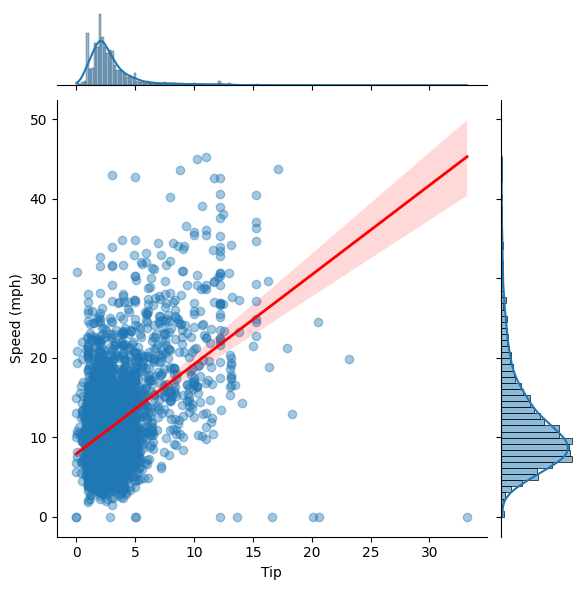

In [7]:
t_copy = taxis.loc[(taxis.tip>0) &  (taxis.speed_mph<150)] 

print('Correlation between tip and speed', t_copy.tip.corr(t_copy.speed_mph))

# Create the joint plot with a regression line and marginal distributions
g = sns.jointplot(
    data=t_copy, 
    x='tip', 
    y='speed_mph', 
    kind='reg',  # "reg" adds both the scatter plot and regression line
    scatter_kws={'alpha': 0.4},  # makes points slightly transparent
    line_kws={'color': 'red', 'linewidth': 2}  # colors the regression line red
)

g.ax_joint.set_xlabel('Tip')
g.ax_joint.set_ylabel('Speed (mph)')

plt.show()

We see that speed has some correlation with the amount of tip given. 

## Questions 

> ### Check the correlation of all the other features. Use correlation matrix plot to visualize.
> ### Can you engineer some new features (domain driven first order features) and see its correlation with the target?


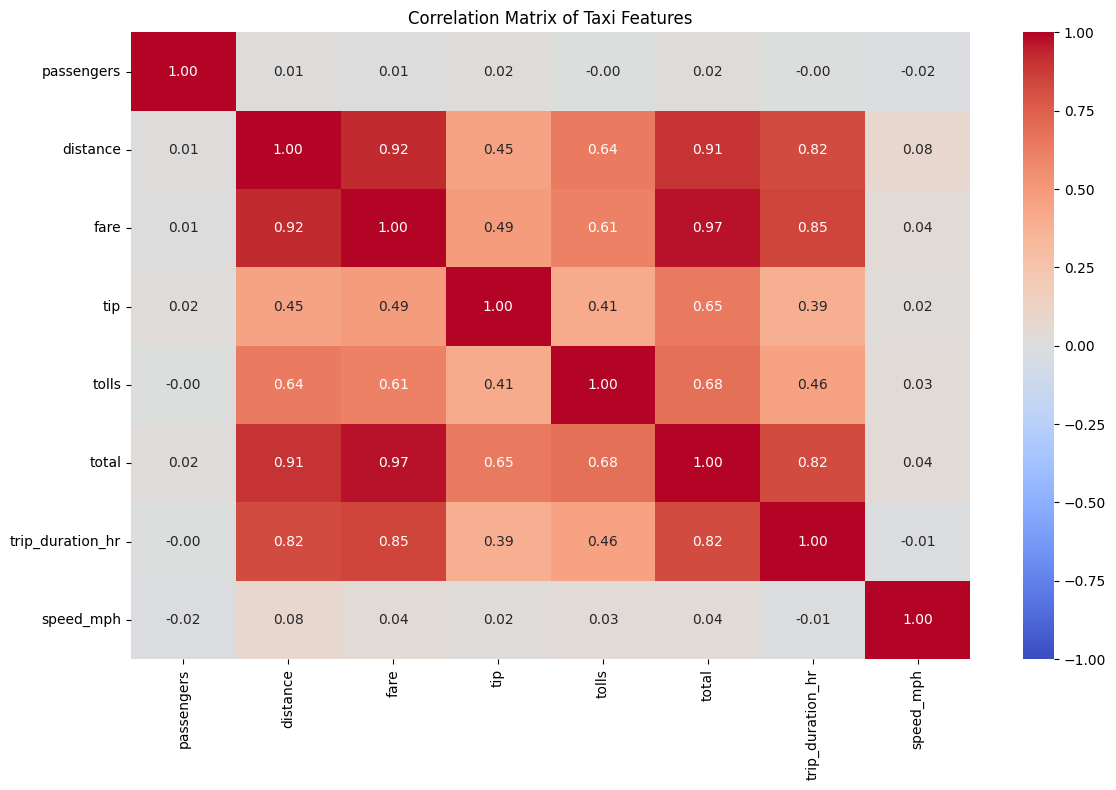

total               0.647280
fare                0.490100
distance            0.452262
tolls               0.413582
trip_duration_hr    0.387188
passengers          0.020769
speed_mph           0.016685
Name: tip, dtype: float64


In [8]:
corr = taxis.select_dtypes(include="number").corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)
plt.title("Correlation Matrix of Taxi Features")
plt.tight_layout()
plt.show()

# Rank features by the strength of their correlation with tip
tip_correlations = corr["tip"].drop("tip")
print(tip_correlations.sort_values(key=abs, ascending=False))

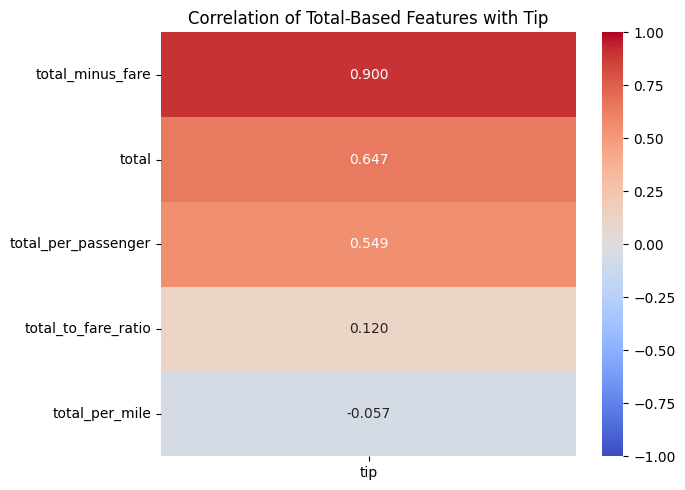

In [9]:
# Prevent division by zero
distance = taxis["distance"].replace(0, np.nan)
passengers = taxis["passengers"].replace(0, np.nan)
fare = taxis["fare"].replace(0, np.nan)

# New features involving total
taxis["total_per_mile"] = taxis["total"] / distance
taxis["total_per_passenger"] = taxis["total"] / passengers
taxis["total_to_fare_ratio"] = taxis["total"] / fare
taxis["total_minus_fare"] = taxis["total"] - taxis["fare"]

features = [
    "total",
    "total_per_mile",
    "total_per_passenger",
    "total_to_fare_ratio",
    "total_minus_fare",
]

# Compare correlations with tip
tip_corr = (
    taxis[features + ["tip"]]
    .corr()["tip"]
    .drop("tip")
    .sort_values(key=abs, ascending=False)
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    tip_corr.to_frame("tip"),
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
)
plt.title("Correlation of Total-Based Features with Tip")
plt.tight_layout()
plt.show()

# Date time derivations

               pickup  year  month  day  day_of_week  is_weekend  hour  \
0 2019-02-28 23:29:03  2019      2   28            3       False    23   
1 2019-03-01 00:03:29  2019      3    1            4       False     0   
2 2019-03-01 00:08:32  2019      3    1            4       False     0   
3 2019-03-01 00:15:53  2019      3    1            4       False     0   
4 2019-03-01 00:29:22  2019      3    1            4       False     0   
5 2019-03-01 00:30:59  2019      3    1            4       False     0   
6 2019-03-01 00:32:49  2019      3    1            4       False     0   
7 2019-03-01 00:53:00  2019      3    1            4       False     0   
8 2019-03-01 00:56:50  2019      3    1            4       False     0   
9 2019-03-01 01:25:30  2019      3    1            4       False     1   

   is_holiday  
0       False  
1       False  
2       False  
3       False  
4       False  
5       False  
6       False  
7       False  
8       False  
9       False  
holiday t

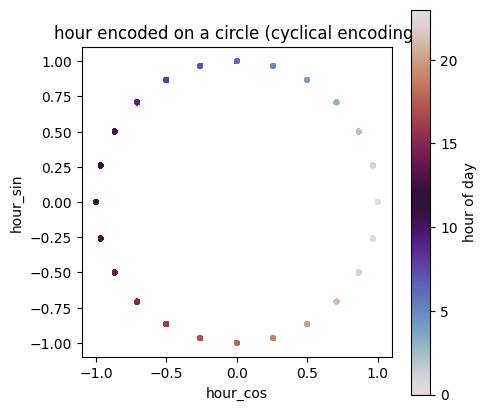

In [10]:
import pandas as pd
import numpy as np
import seaborn as sns
from pandas.tseries.holiday import USFederalHolidayCalendar
import matplotlib.pyplot as plt

taxis = sns.load_dataset("taxis").dropna(subset=["pickup"]).copy()
taxis = taxis.sort_values("pickup").reset_index(drop=True)

# ── calendar-part derivations ────────────────────────────────────────────
taxis["year"] = taxis.pickup.dt.year
taxis["month"] = taxis.pickup.dt.month
taxis["day"] = taxis.pickup.dt.day
taxis["day_of_week"] = taxis.pickup.dt.dayofweek     # 0=Mon ... 6=Sun
taxis["is_weekend"] = taxis.day_of_week >= 5
taxis["hour"] = taxis.pickup.dt.hour

cal = USFederalHolidayCalendar()                      # built into pandas, no download needed
holidays = cal.holidays(start=taxis.pickup.min(), end=taxis.pickup.max())
taxis["is_holiday"] = taxis.pickup.dt.normalize().isin(holidays)

print(taxis[["pickup", "year", "month", "day", "day_of_week", "is_weekend", "hour", "is_holiday"]].head(10))
print("holiday trips:", taxis.is_holiday.sum(), "/", len(taxis))

# ── time since an event ──────────────────────────────────────────────────
# (a) recency within a group — same pattern as days_since_last_purchase per customer.
#     taxis has no customer id, so pickup_zone stands in as the repeated entity.
taxis["hours_since_last_pickup_in_zone"] = (
    taxis.groupby("pickup_zone")["pickup"].diff().dt.total_seconds() / 3600
)

# (b) age-style feature — reference_date - event_date (same shape as today - birth_date)
reference_date = taxis.pickup.max() + pd.Timedelta(days=1)   # stand-in for "today"
taxis["days_since_pickup"] = (reference_date - taxis.pickup).dt.total_seconds() / 86400

print(taxis[["pickup_zone", "pickup", "hours_since_last_pickup_in_zone", "days_since_pickup"]].head(10))

# ── cyclical encoding ─────────────────────────────────────────────────────
taxis["hour_sin"] = np.sin(2 * np.pi * taxis.hour / 24)
taxis["hour_cos"] = np.cos(2 * np.pi * taxis.hour / 24)

day_of_year = taxis.pickup.dt.dayofyear
days_in_year = np.where(taxis.pickup.dt.is_leap_year, 366, 365)
taxis["doy_sin"] = np.sin(2 * np.pi * day_of_year / days_in_year)
taxis["doy_cos"] = np.cos(2 * np.pi * day_of_year / days_in_year)

# 23:00 and 00:00 are 1 hour apart in reality, but 23 vs 0 on a raw scale look 23 apart.
# sin/cos map both onto neighboring points on a circle instead:
for h in [23, 0, 1]:
    row = taxis[taxis.hour == h].iloc[0]
    print(f"hour={h:>2}  sin={row.hour_sin:.2f}  cos={row.hour_cos:.2f}")

plt.figure(figsize=(5, 5))
plt.scatter(taxis.hour_cos, taxis.hour_sin, c=taxis.hour, cmap="twilight", s=8)
plt.gca().set_aspect("equal")
plt.title("hour encoded on a circle (cyclical encoding)")
plt.xlabel("hour_cos"); plt.ylabel("hour_sin")
plt.colorbar(label="hour of day")
plt.show()


In [11]:
print(taxis.loc[taxis.is_weekend, 'tip'].mean())
print(taxis.loc[~taxis.is_weekend, 'tip'].mean())

1.8575757575757574
2.0307413144500996


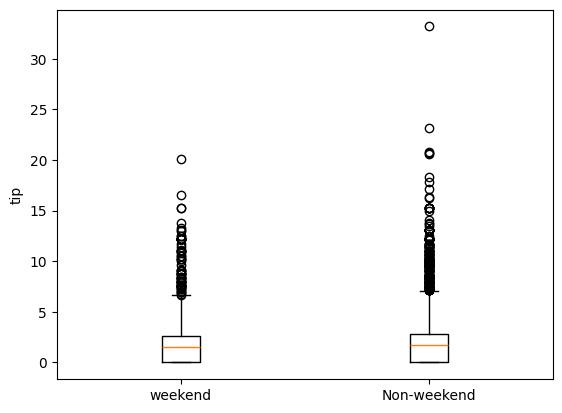

In [12]:
data = [
    taxis.loc[taxis.is_weekend, 'tip'].dropna(),
    taxis.loc[~taxis.is_weekend, 'tip'].dropna(),
]

plt.boxplot(data, tick_labels=['weekend', 'Non-weekend'])
plt.ylabel('tip')
plt.show()

## Questions 
### Can you see correlation of other date time features with the Tip ?
### Plot a scatter plot of fare_per_mile vs time of the pick up (you can create extra feature such as night or day)
### Can you see some seasonality in the Tip and time of the year or time/day of the week ? (evolution of tip across months, day of the week )

hours_since_last_pickup_in_zone   -0.113
hour_cos                           0.041
hour_sin                          -0.034
hour                               0.033
is_weekend                        -0.032
day_of_week                       -0.026
doy_sin                            0.021
days_since_pickup                 -0.019
doy_cos                           -0.018
day                                0.017
month                              0.010
Name: tip, dtype: float64


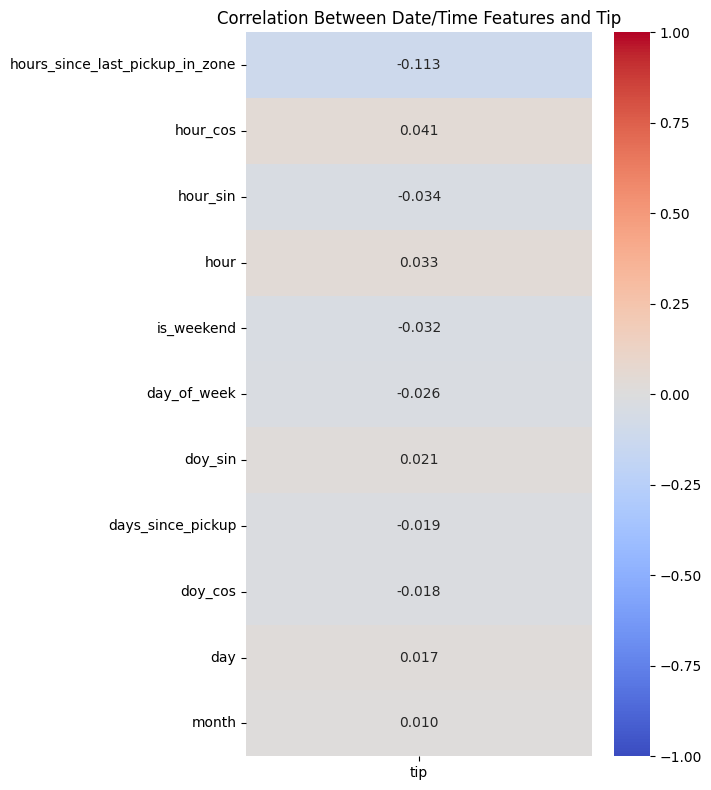

In [13]:
datetime_features = [
    "year",
    "month",
    "day",
    "day_of_week",
    "is_weekend",
    "hour",
    "is_holiday",
    "hours_since_last_pickup_in_zone",
    "days_since_pickup",
    "hour_sin",
    "hour_cos",
    "doy_sin",
    "doy_cos",
]

# Keep features that vary across trips
varying_features = [
    col for col in datetime_features
    if taxis[col].nunique() > 1
]

# Calculate and rank correlations with tip
tip_corr = (
    taxis[varying_features + ["tip"]]
    .corr(numeric_only=False)["tip"]
    .drop("tip")
    .sort_values(key=abs, ascending=False)
)

print(tip_corr.round(3))

plt.figure(figsize=(7, 8))
sns.heatmap(
    tip_corr.to_frame("tip"),
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)
plt.title("Correlation Between Date/Time Features and Tip")
plt.tight_layout()
plt.show()

-> Low correlation between time features and tip

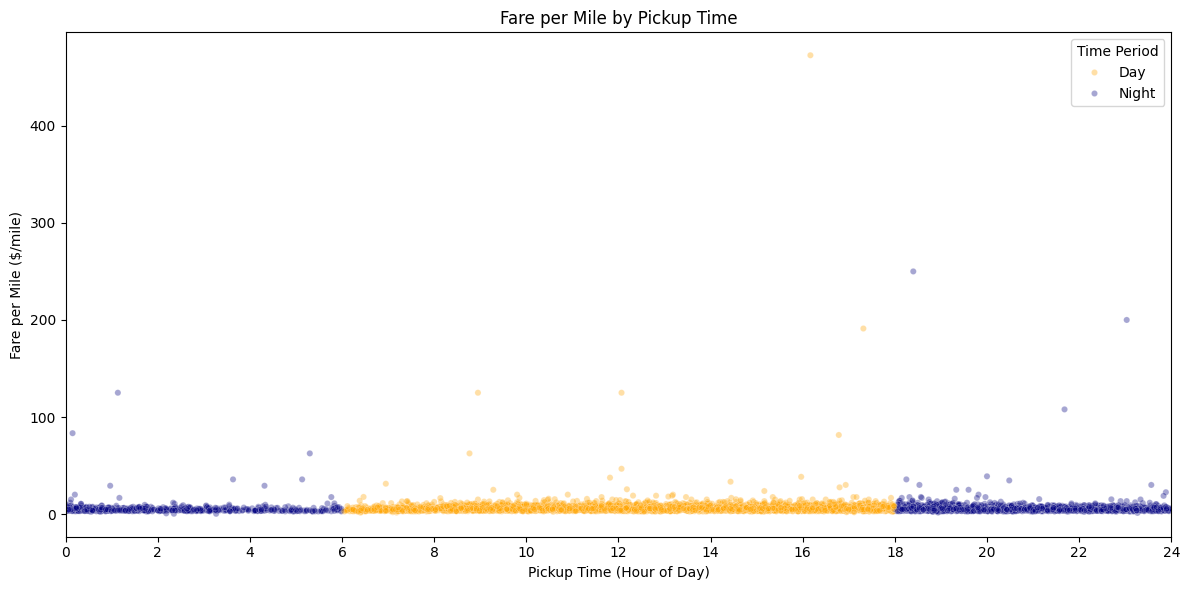

In [14]:
taxis["pickup"] = pd.to_datetime(taxis["pickup"])

# Calculate fare per mile, excluding zero or negative distances
taxis["fare_per_mile"] = taxis["fare"] / taxis["distance"].where(
    taxis["distance"] > 0
)

# Include minutes to show pickup time more precisely
taxis["pickup_hour"] = (
    taxis["pickup"].dt.hour + taxis["pickup"].dt.minute / 60
)

taxis["day_or_night"] = np.where(
    taxis["pickup_hour"].between(6, 18, inclusive="left"),
    "Day",
    "Night",
)

plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=taxis,
    x="pickup_hour",
    y="fare_per_mile",
    hue="day_or_night",
    hue_order=["Day", "Night"],
    palette={"Day": "orange", "Night": "navy"},
    alpha=0.35,
    s=20,
)

plt.xlabel("Pickup Time (Hour of Day)")
plt.ylabel("Fare per Mile ($/mile)")
plt.title("Fare per Mile by Pickup Time")
plt.xticks(range(0, 25, 2))
plt.xlim(0, 24)
plt.legend(title="Time Period")
plt.tight_layout()
plt.show()

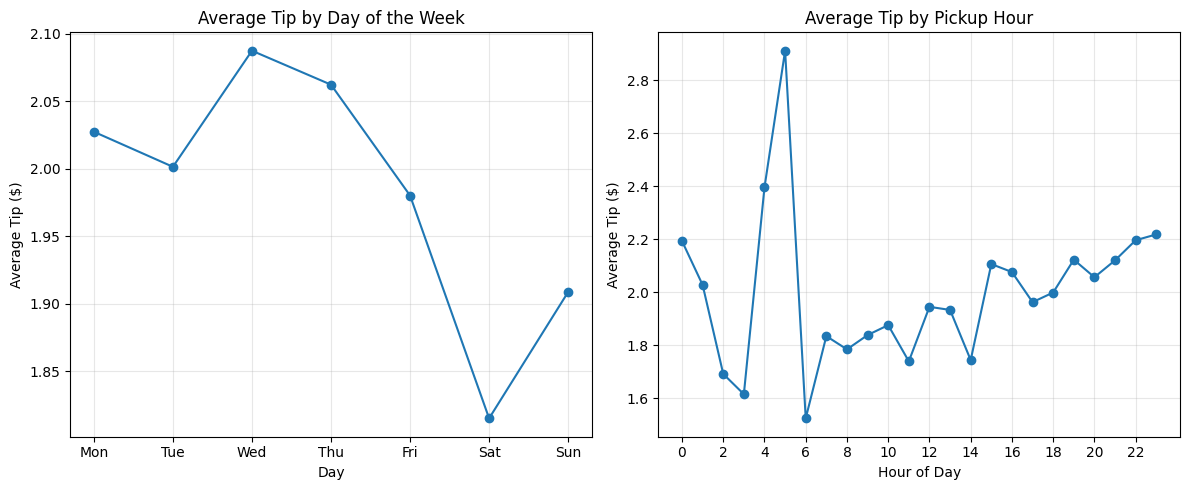

In [15]:
taxis["pickup"] = pd.to_datetime(taxis["pickup"])

taxis["day_of_week"] = taxis["pickup"].dt.dayofweek
taxis["hour"] = taxis["pickup"].dt.hour

fig, axes = plt.subplots(1, 2, figsize=(12, 5))


# Average tip by day of the week
weekday_tips = (
    taxis.groupby("day_of_week")["tip"]
    .mean()
    .reindex(range(7))
)
axes[0].plot(weekday_tips.index, weekday_tips.values, marker="o")
axes[0].set_title("Average Tip by Day of the Week")
axes[0].set_xlabel("Day")
axes[0].set_xticks(range(7))
axes[0].set_xticklabels(
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
)

# Average tip by pickup hour
hourly_tips = (
    taxis.groupby("hour")["tip"]
    .mean()
    .reindex(range(24))
)
axes[1].plot(hourly_tips.index, hourly_tips.values, marker="o")
axes[1].set_title("Average Tip by Pickup Hour")
axes[1].set_xlabel("Hour of Day")
axes[1].set_xticks(range(0, 24, 2))

for ax in axes:
    ax.set_ylabel("Average Tip ($)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
taxis["day"] = taxis.pickup.dt.day

taxis


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,...,is_holiday,hours_since_last_pickup_in_zone,days_since_pickup,hour_sin,hour_cos,doy_sin,doy_cos,fare_per_mile,pickup_hour,day_or_night
0,2019-02-28 23:29:03,2019-02-28 23:32:35,1,0.90,5.0,0.00,0.0,6.30,green,cash,...,False,NaN,32.010208,-0.258819,0.965926,0.849817,0.527078,5.555556,23.483333,Night
1,2019-03-01 00:03:29,2019-03-01 00:13:32,3,2.16,10.0,2.00,0.0,15.80,yellow,credit card,...,False,NaN,31.986296,0.000000,1.000000,0.858764,0.512371,4.629630,0.050000,Night
2,2019-03-01 00:08:32,2019-03-01 00:29:47,3,7.35,22.5,1.00,0.0,27.30,yellow,credit card,...,False,NaN,31.982789,0.000000,1.000000,0.858764,0.512371,3.061224,0.133333,Night
3,2019-03-01 00:15:53,2019-03-01 00:47:58,1,7.00,25.5,7.30,0.0,36.60,yellow,credit card,...,False,NaN,31.977685,0.000000,1.000000,0.858764,0.512371,3.642857,0.250000,Night
4,2019-03-01 00:29:22,2019-03-01 00:32:48,4,0.74,4.5,1.00,0.0,9.30,yellow,credit card,...,False,NaN,31.968322,0.000000,1.000000,0.858764,0.512371,6.081081,0.483333,Night
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 22:13:37,2019-03-31 22:22:50,1,1.00,7.5,0.70,0.0,12.00,yellow,credit card,...,False,1.291389,1.062593,-0.500000,0.866025,0.999769,0.021516,7.500000,22.216667,Night
6429,2019-03-31 22:32:27,2019-03-31 22:34:45,1,0.40,3.5,1.45,0.0,8.75,yellow,credit card,...,False,19.688056,1.049514,-0.500000,0.866025,0.999769,0.021516,8.750000,22.533333,Night
6430,2019-03-31 22:51:53,2019-03-31 22:55:10,1,0.67,4.5,1.66,0.0,9.96,yellow,credit card,...,False,1.273333,1.036019,-0.500000,0.866025,0.999769,0.021516,6.716418,22.850000,Night
6431,2019-03-31 23:15:03,2019-03-31 23:27:12,1,3.03,11.5,3.82,0.0,19.12,yellow,credit card,...,False,8.457500,1.019931,-0.258819,0.965926,0.999769,0.021516,3.795380,23.250000,Night


# Text features

**Dataset description:** **Titanic dataset**

Real 1912 passenger manifest: name, ticket, cabin, class, fare, family size, and survival outcome. Target is survived — discrete/binary (0 = died, 1 = survived).

This dataset has a lot of missing values for age column. 

We can infer the ages of missing passengers using names column.

Here we extracted the titles from the names. 

The mean/median age of each title can then be used to fill the missing values. 

In [17]:
import re
import pandas as pd
from sklearn.datasets import fetch_openml

titanic = fetch_openml(name="titanic", version=1, as_frame=True).frame
titanic["survived"] = pd.to_numeric(titanic["survived"])

# ── basic string-derived features (on the free-text 'name' field) ────────
titanic["name_length"] = titanic.name.str.len()
titanic["name_word_count"] = titanic.name.str.split().str.len()
titanic["name_digit_count"] = titanic.name.str.count(r"\d")
titanic["name_punct_count"] = titanic.name.str.count(r"[^\w\s]")
titanic["name_punct_ratio"] = titanic.name_punct_count / titanic.name_length

titanic[["name", "name_length", "name_word_count", "name_digit_count", "name_punct_ratio"]].head(10)


,name,name_length,name_word_count,name_digit_count,name_punct_ratio
0,"Allen, Miss. Elisabeth Walton",29,4,0,0.068966
1,"Allison, Master. Hudson Trevor",30,4,0,0.066667
2,"Allison, Miss. Helen Loraine",28,4,0,0.071429
3,"Allison, Mr. Hudson Joshua Creighton",36,5,0,0.055556
4,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",47,8,0,0.085106
5,"Anderson, Mr. Harry",19,3,0,0.105263
6,"Andrews, Miss. Kornelia Theodosia",33,4,0,0.060606
7,"Andrews, Mr. Thomas Jr",22,4,0,0.090909
8,"Appleton, Mrs. Edward Dale (Charlotte Lamson)",45,6,0,0.088889
9,"Artagaveytia, Mr. Ramon",23,3,0,0.086957


In [18]:
titanic.head(5)

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest,name_length,name_word_count,name_digit_count,name_punct_count,name_punct_ratio
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO",29,4,0,2,0.068966
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON",30,4,0,2,0.066667
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON",28,4,0,2,0.071429
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON",36,5,0,2,0.055556
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON",47,8,0,4,0.085106


In [19]:

# ── regex-extracted field #1: title, pulled out of free text ─────────────
titanic["title"] = titanic.name.str.extract(r",\s*([^\.]+)\.")

In [20]:


print(titanic.groupby("title")["survived"].mean().sort_values(ascending=False))
# 

title
Lady            1.000000
Dona            1.000000
the Countess    1.000000
Sir             1.000000
Mme             1.000000
Mlle            1.000000
Mrs             0.786802
Miss            0.676923
Master          0.508197
Col             0.500000
Major           0.500000
Ms              0.500000
Dr              0.500000
Mr              0.162483
Capt            0.000000
Jonkheer        0.000000
Don             0.000000
Rev             0.000000
Name: survived, dtype: float64


## Questions:

* ### Can you do missing values plots from msno library and see which feature values are missing.
* ### Try the values imputation and deletion treatments for the missing values and see the effects on the correlation.
* ### Can you impute missing ages by average of each age of the same title (new feature we just created)
* ### Can you create a feature based on the last name of passenger, "if_relative_present", and compute its AUC with target 
* ### Compare AUC of all features. which one is highest predictability

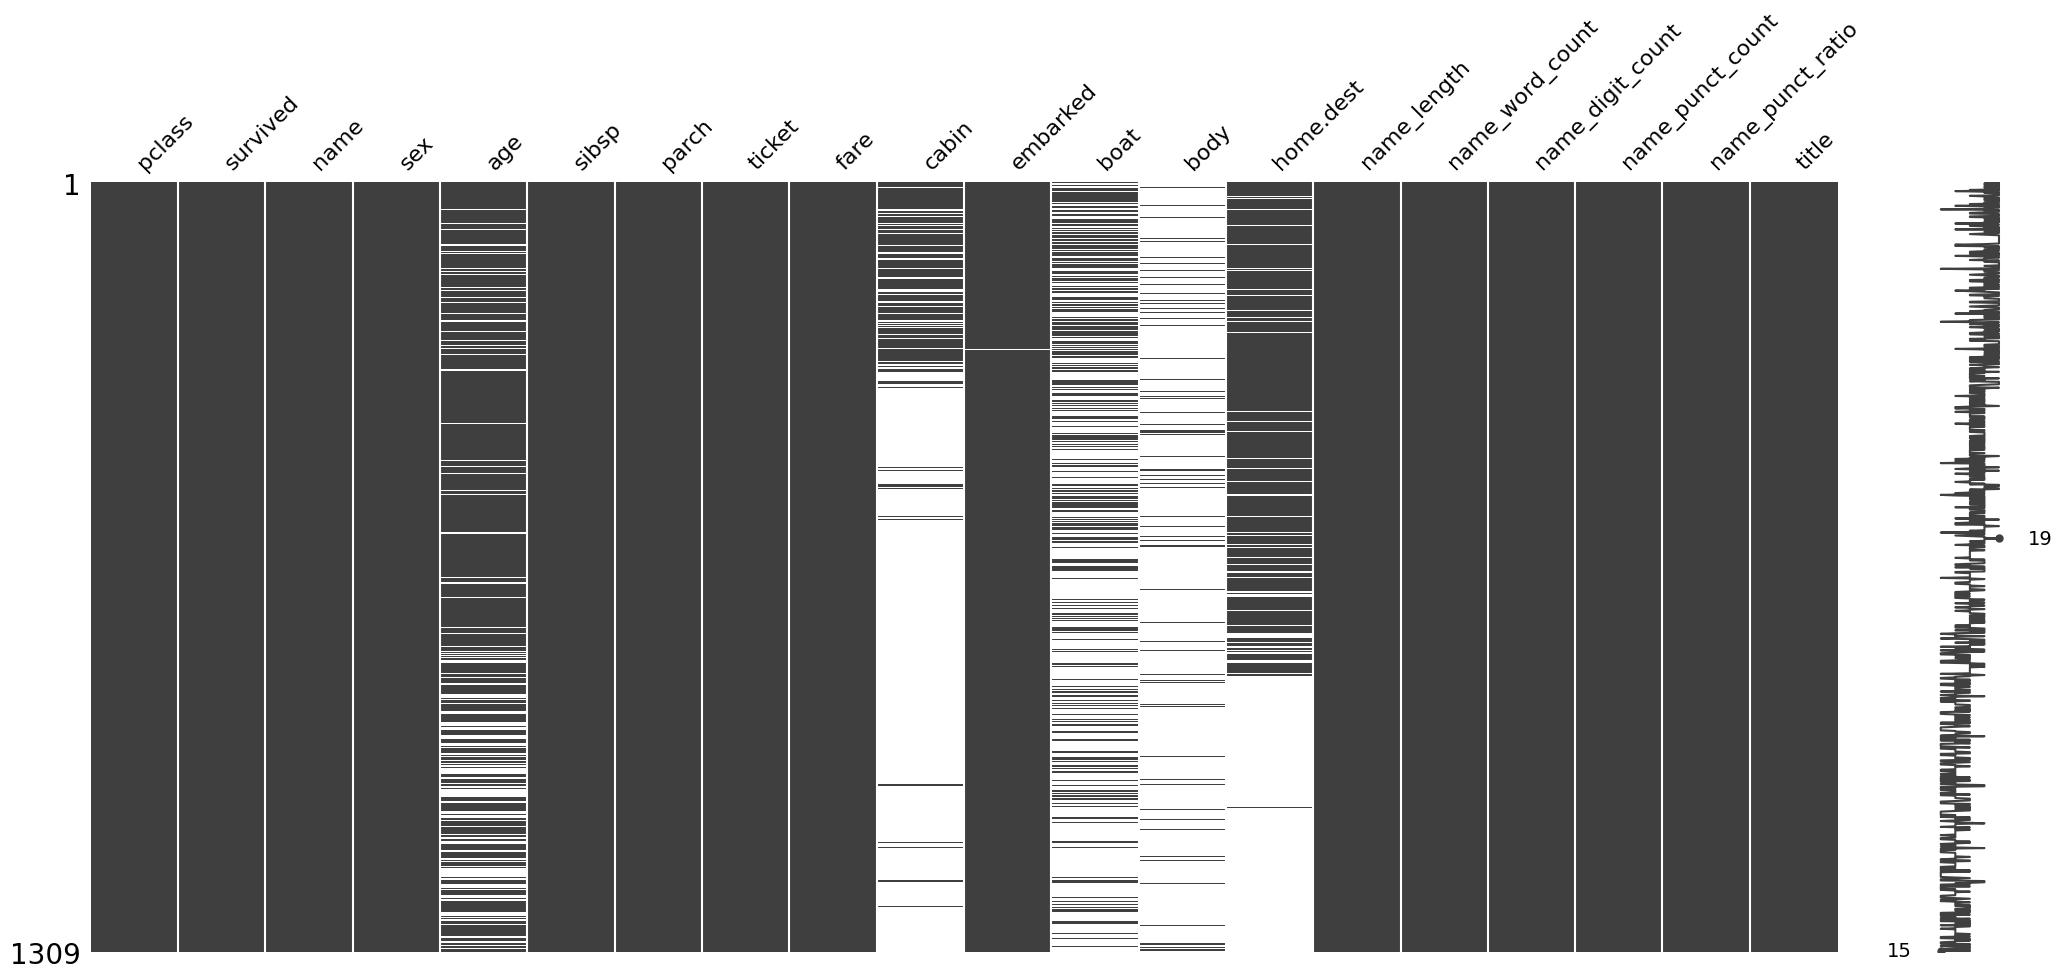

In [21]:
import missingno as msno
msno.matrix(titanic)
plt.show()

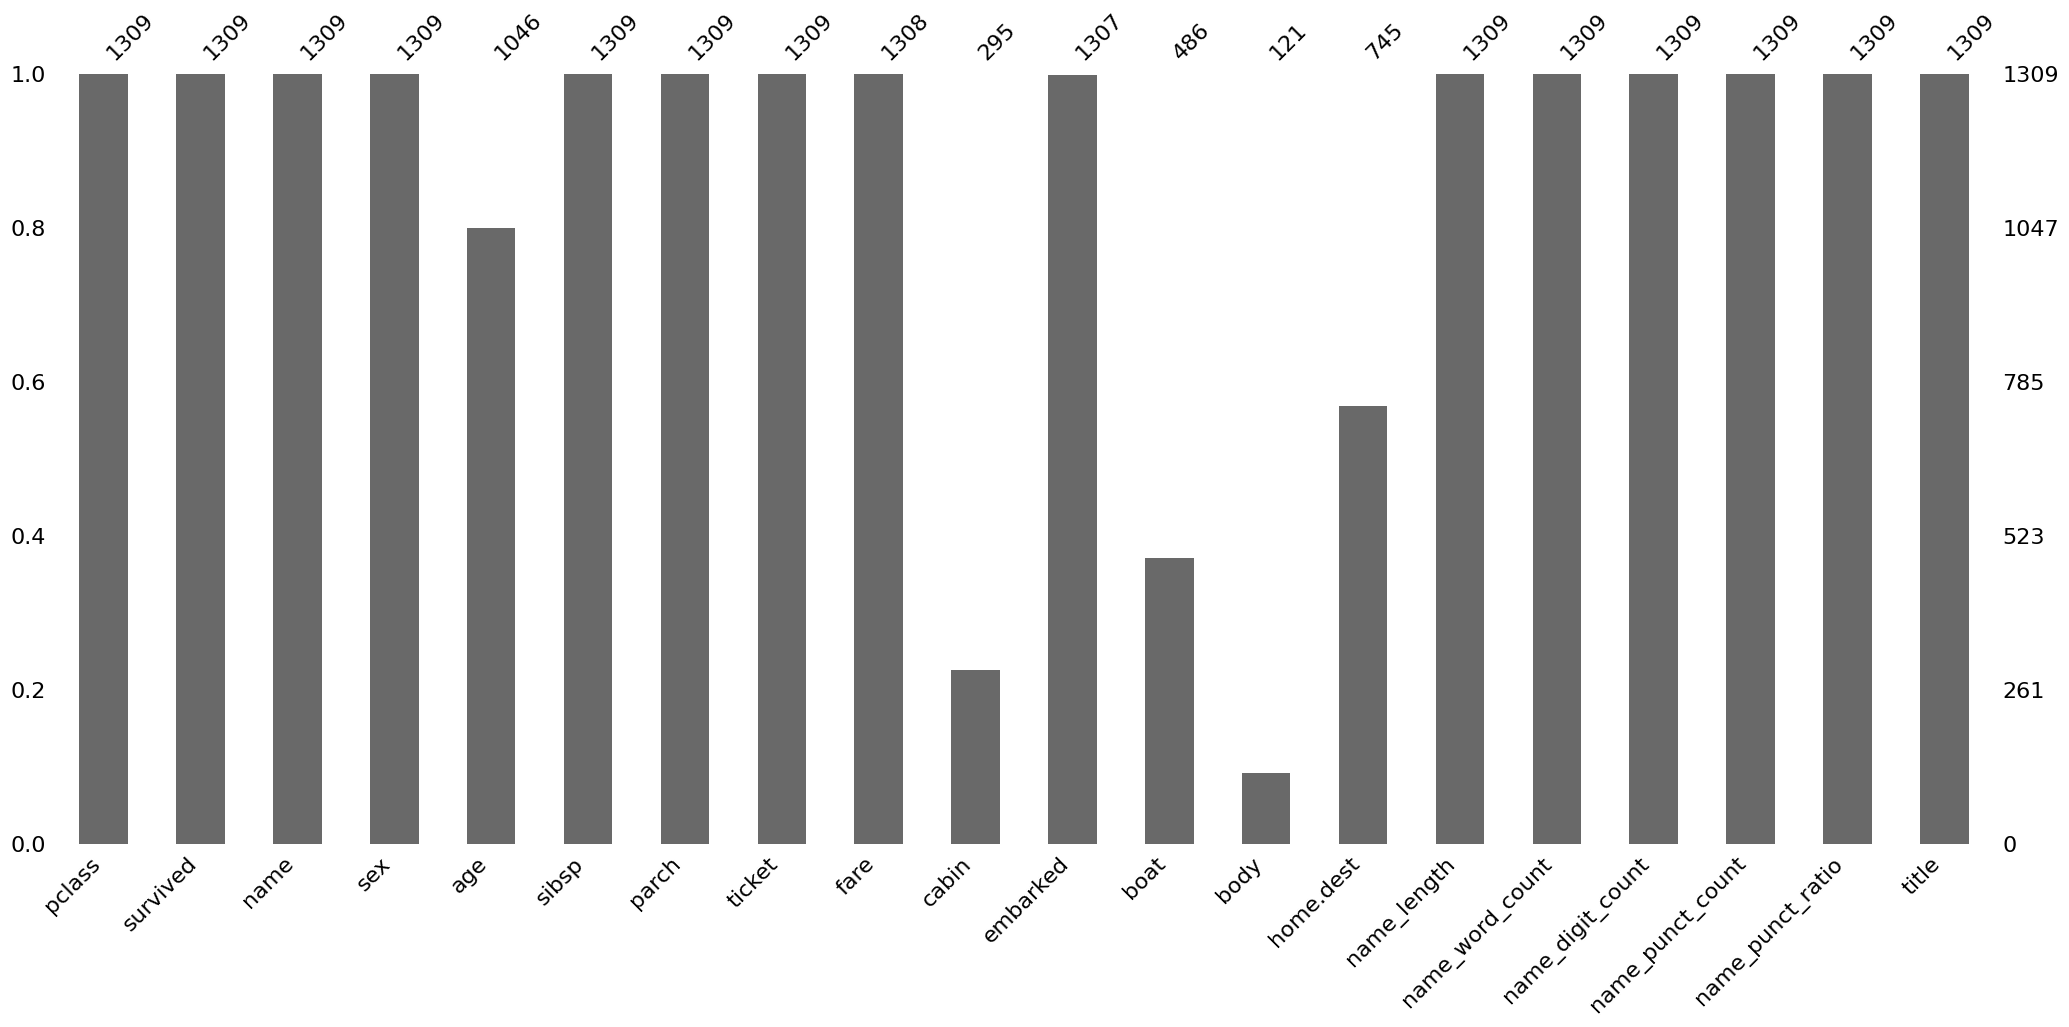

pclass                 0
survived               0
name                   0
sex                    0
age                  263
sibsp                  0
parch                  0
ticket                 0
fare                   1
cabin               1014
embarked               2
boat                 823
body                1188
home.dest            564
name_length            0
name_word_count        0
name_digit_count       0
name_punct_count       0
name_punct_ratio       0
title                  0
dtype: int64

In [22]:
msno.bar(titanic)
plt.show()
titanic.isnull().sum()

Missing values before treatment:
pclass                0
age                 263
sibsp                 0
parch                 0
fare                  1
name_length           0
name_word_count       0
name_punct_count      0
name_punct_ratio      0
dtype: int64

Original rows: 1309
Rows after imputation: 1309
Rows after deletion: 1045

Correlation with survived:
                  Original  Median imputation  Row deletion
pclass              -0.312             -0.312        -0.320
age                 -0.056             -0.044        -0.054
sibsp               -0.028             -0.028        -0.013
parch                0.083              0.083         0.114
fare                 0.244              0.244         0.249
name_length          0.352              0.352         0.348
name_word_count      0.311              0.311         0.307
name_punct_count     0.347              0.347         0.367
name_punct_ratio     0.023              0.023         0.057


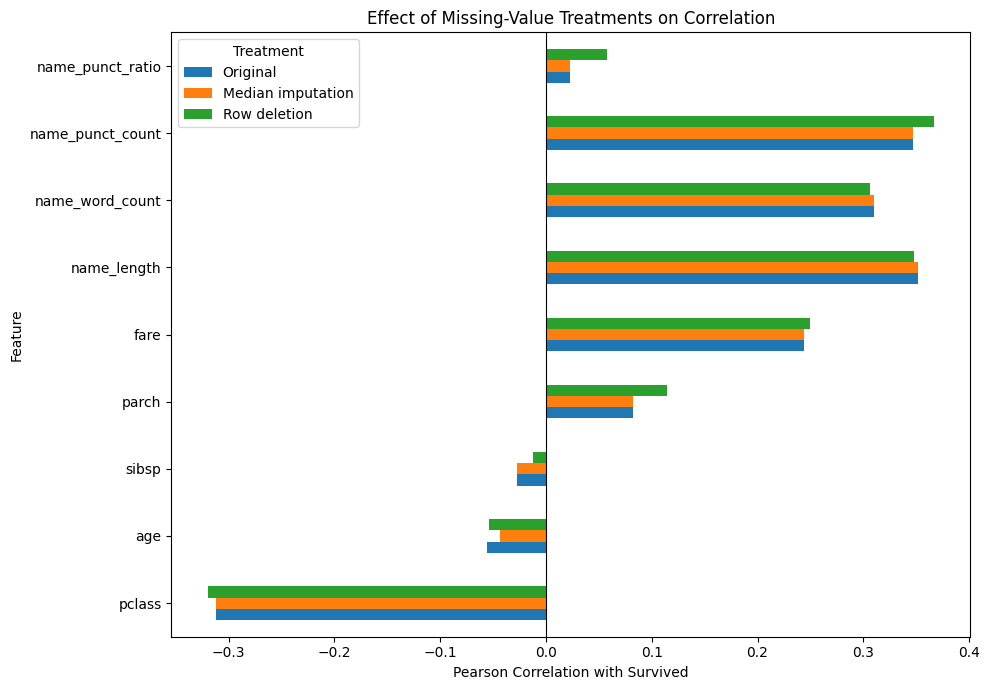

In [23]:
features = [
    "pclass", "age", "sibsp", "parch", "fare",
    "name_length", "name_word_count",
    "name_punct_count", "name_punct_ratio",
]

data = titanic[features + ["survived"]].apply(
    pd.to_numeric, errors="coerce"
)

# Remove rows with missing targets; never impute the target
data = data.dropna(subset=["survived"])

# 1. Imputation: replace missing feature values with column medians
imputed = data.copy()
imputed[features] = imputed[features].fillna(
    imputed[features].median()
)

# 2. Deletion: remove rows missing any selected feature
deleted = data.dropna(subset=features)

# Compare each feature's correlation with survival
correlations = pd.DataFrame({
    "Original": data[features].corrwith(data["survived"]),
    "Median imputation": imputed[features].corrwith(imputed["survived"]),
    "Row deletion": deleted[features].corrwith(deleted["survived"]),
})

print("Missing values before treatment:")
print(data[features].isna().sum())

print(f"\nOriginal rows: {len(data)}")
print(f"Rows after imputation: {len(imputed)}")
print(f"Rows after deletion: {len(deleted)}")

print("\nCorrelation with survived:")
print(correlations.round(3))

correlations.plot.barh(figsize=(10, 7))
plt.xlabel("Pearson Correlation with Survived")
plt.ylabel("Feature")
plt.title("Effect of Missing-Value Treatments on Correlation")
plt.axvline(0, color="black", linewidth=0.8)
plt.legend(title="Treatment")
plt.tight_layout()
plt.show()

In [24]:
missing_before = titanic["age"].isna().sum()

# Calculate the mean age for each passenger's title
mean_age_by_title = titanic.groupby("title")["age"].transform("mean")
overall_mean_age = titanic["age"].mean()

# Fill missing ages, preserving existing values
titanic["age"] = (
    titanic["age"]
    .fillna(mean_age_by_title)
    .fillna(overall_mean_age)
)

print(f"Missing ages before: {missing_before}")
print(f"Missing ages after:  {titanic['age'].isna().sum()}")

Missing ages before: 263
Missing ages after:  0


In [27]:
from sklearn.metrics import roc_auc_score

titanic["last_name"] = (
    titanic["name"]
    .str.split(",", n=1)
    .str[0]
    .str.strip()
    .str.casefold()
    .replace("", None)
)

# Flag passengers whose surname appears more than once
surname_counts = titanic["last_name"].value_counts()

titanic["if_relative_present"] = (
    titanic["last_name"].map(surname_counts).fillna(0) > 1
).astype(int)

# Calculate AUC using passengers with known survival outcomes
valid = titanic["survived"].notna()

auc = roc_auc_score(
    titanic.loc[valid, "survived"].astype(int),
    titanic.loc[valid, "if_relative_present"],
)

print(f"AUC of if_relative_present: {auc:.3f}")

print(
    titanic.groupby("if_relative_present")["survived"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "survival_rate"})
)

AUC of if_relative_present: 0.556
                     count  survival_rate
if_relative_present                      
0                      637       0.328100
1                      672       0.433036


            Feature   AUC  Direction-adjusted AUC  Rows used
         sex_female 0.761                   0.761       1309
        name_length 0.694                   0.694       1309
               fare 0.675                   0.675       1308
   name_punct_count 0.659                   0.659       1309
    name_word_count 0.654                   0.654       1309
          title_Mrs 0.629                   0.629       1309
         title_Miss 0.624                   0.624       1309
         pclass_1.0 0.624                   0.624       1309
         embarked_C 0.576                   0.576       1309
              parch 0.571                   0.571       1309
if_relative_present 0.556                   0.556       1309
              sibsp 0.541                   0.541       1309
         pclass_2.0 0.521                   0.521       1309
       title_Master 0.512                   0.512       1309
         title_Mlle 0.502                   0.502       1309
       embarked_nan 0.50

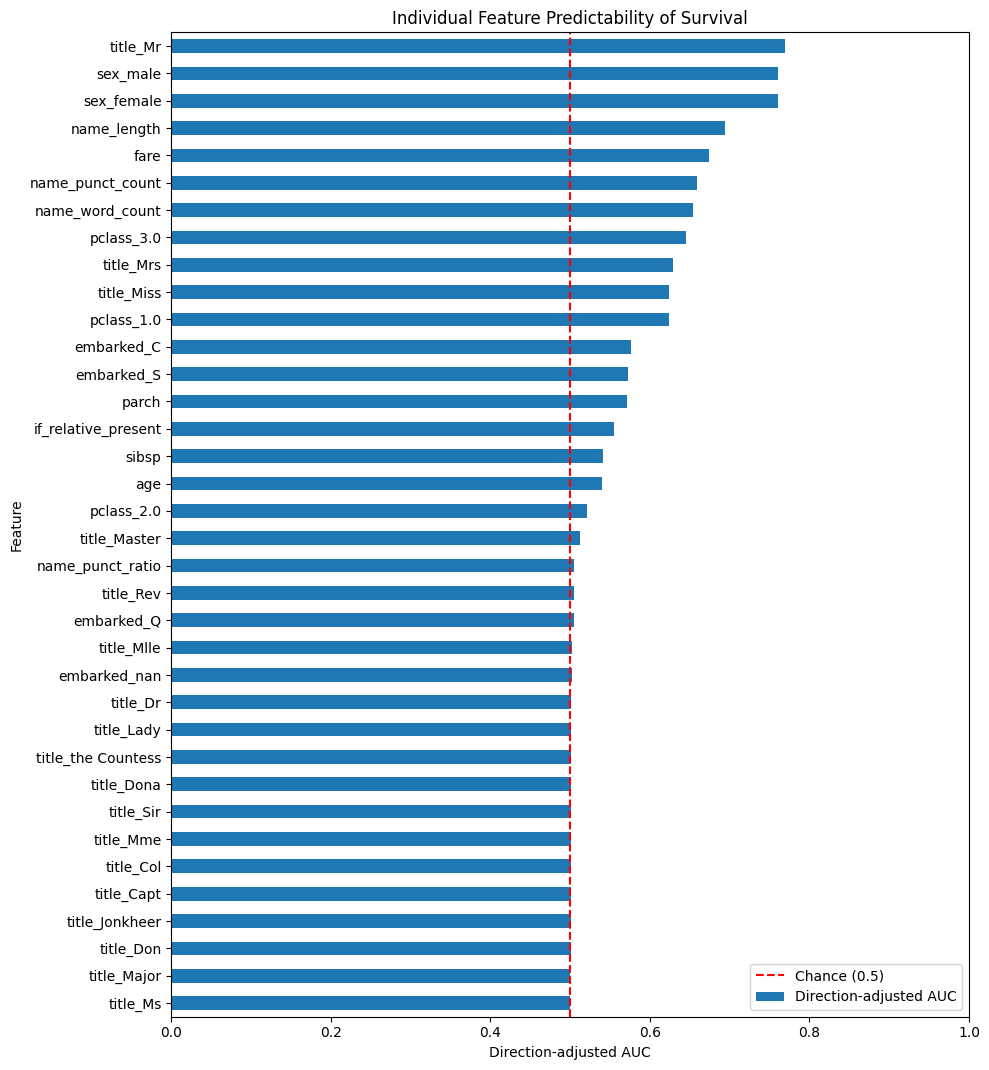

In [28]:
X = titanic.select_dtypes(include=["number", "bool"]).drop(
    columns=["survived", "boat", "body"],
    errors="ignore",
).copy()

# Encode categorical features as binary indicators
categorical_cols = ["pclass", "sex", "embarked", "title"]
X = X.drop(columns=categorical_cols, errors="ignore")

X = pd.concat([
    X,
    pd.get_dummies(
        titanic[categorical_cols],
        columns=categorical_cols,
        dummy_na=True,
        dtype=int,
    ),
], axis=1)

y = pd.to_numeric(titanic["survived"], errors="coerce")

results = []

for feature in X.columns:
    # Use rows where both the feature and target are available
    valid = X[feature].notna() & y.notna()

    if y[valid].nunique() < 2 or X.loc[valid, feature].nunique() < 2:
        continue

    auc = roc_auc_score(y[valid], X.loc[valid, feature])

    results.append({
        "Feature": feature,
        "AUC": auc,
        # Account for features where lower values predict survival
        "Direction-adjusted AUC": max(auc, 1 - auc),
        "Rows used": int(valid.sum()),
    })

auc_results = (
    pd.DataFrame(results)
    .sort_values("AUC", ascending=False)
    .reset_index(drop=True)
)

print(auc_results.round(3).to_string(index=False))

best = auc_results.iloc[0]
print(
    f"\nMost predictive feature: {best['Feature']} "
    f"(direction-adjusted AUC = {best['Direction-adjusted AUC']:.3f})"
)

# Plot the ranked results
plot_data = auc_results.set_index("Feature")[
    "Direction-adjusted AUC"
].sort_values()

plot_data.plot.barh(figsize=(10, max(6, len(plot_data) * 0.3)))
plt.axvline(0.5, color="red", linestyle="--", label="Chance (0.5)")
plt.xlabel("Direction-adjusted AUC")
plt.title("Individual Feature Predictability of Survival")
plt.xlim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

Note: This is not the features AUC predictability of survival, but the strenght of each feature to predict whether the passenger survived or not, hence title_Mr ranks best for predictability, despite have the worst correlation with survivability

In [29]:
def plot_survival_rate(df, feature):
    df.groupby(feature)["survived"].mean().plot(kind="bar")

    plt.xlabel(feature)
    plt.ylabel("Survival Rate")
    plt.title(f"Survival Rate by {feature}")
    #plt.ylim(0, 1)
    plt.show()

/tmp/ipykernel_58/1263488353.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(feature)["survived"].mean().plot(kind="bar")


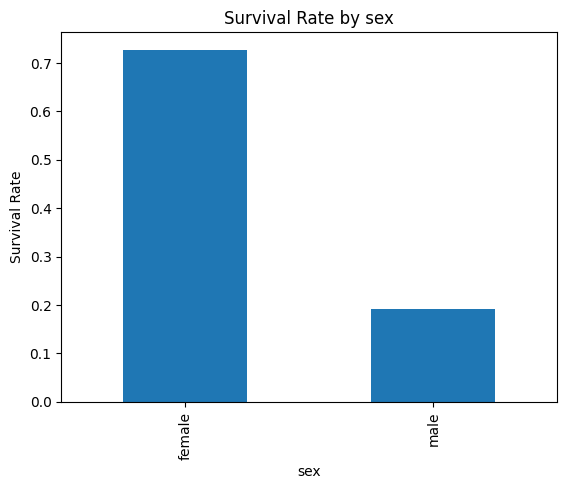

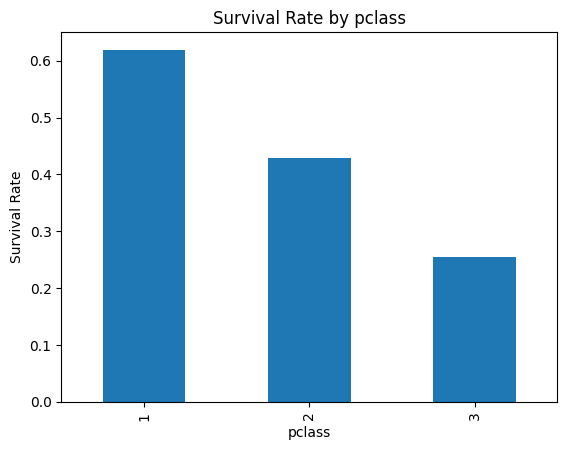

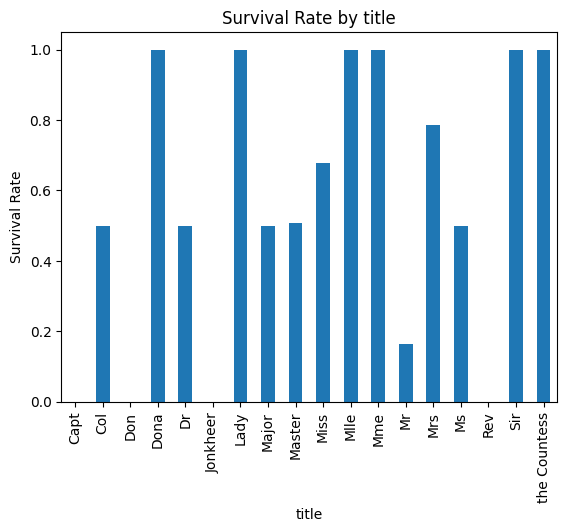

/tmp/ipykernel_58/1263488353.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(feature)["survived"].mean().plot(kind="bar")


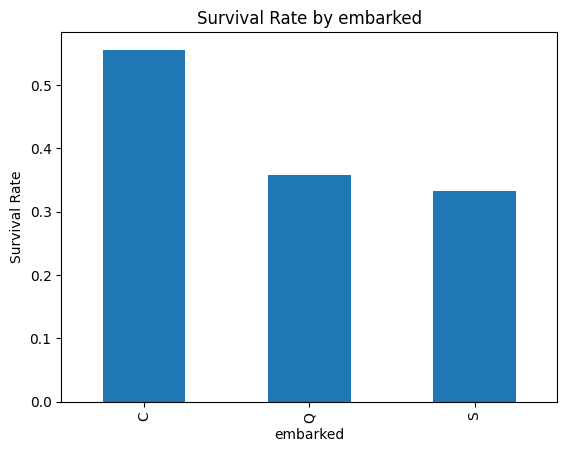

In [30]:
plot_survival_rate(titanic, "sex")
plot_survival_rate(titanic, "pclass")
plot_survival_rate(titanic, "title")
plot_survival_rate(titanic, "embarked")



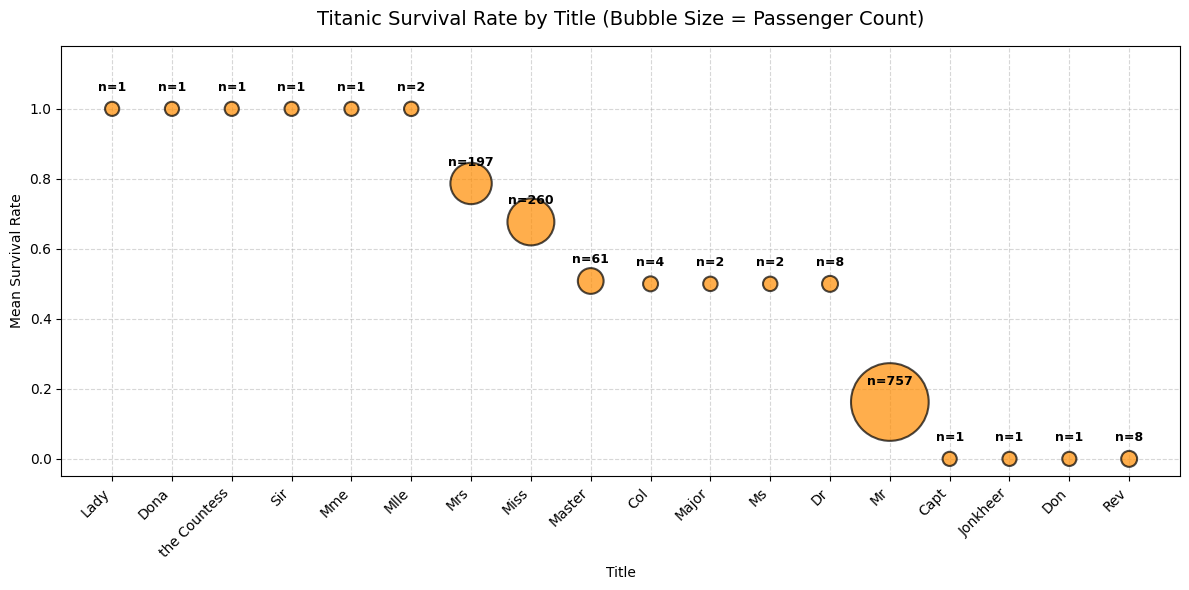

In [31]:
import matplotlib.pyplot as plt

# Calculate survival mean and count
grouped = titanic.groupby("title")["survived"].agg(["mean", "count"]).sort_values(by="mean", ascending=False)

plt.figure(figsize=(12, 6))

# Map passenger counts to marker size (adding a base of 100 so small counts are still clickable/visible)
sizes = grouped["count"] * 4 + 100

# Plot bubbles
plt.scatter(range(len(grouped)), grouped["mean"], s=sizes, color="darkorange", alpha=0.7, edgecolors="black", linewidths=1.5, zorder=3)

# Label x-axis
plt.xticks(ticks=range(len(grouped)), labels=grouped.index, rotation=45, ha="right")

# Annotate bubble count
for i, (idx, row) in enumerate(grouped.iterrows()):
    plt.text(i, row["mean"] + 0.05, f"n={int(row['count'])}", ha="center", fontsize=9, fontweight="bold")

plt.ylabel("Mean Survival Rate")
plt.xlabel("Title")
plt.title("Titanic Survival Rate by Title (Bubble Size = Passenger Count)", fontsize=14, pad=15)
plt.ylim(-0.05, 1.18)  # Leave room for annotations
plt.grid(True, linestyle="--", alpha=0.5, zorder=1)
plt.tight_layout()
plt.show()


# Interaction features

**Dataset description:** **California housing dataset**

 Real 1990 census block-group data: median income, room/bedroom/occupancy averages, location, and house value. 
 
 **Target is MedHouseVal — continuous (median house value, in units of $100,000s).**

 Here we derived new features using simple ratio, difference and product operation of the existing features. 


In [32]:
import pandas as pd
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True).frame
# columns: MedInc, HouseAge, AveRooms, AveBedrooms, Population, AveOccup,
#          Latitude, Longitude, MedHouseVal (target)

# recover an actual household count from two averaged columns (ratio)
housing["households"] = housing.Population / housing.AveOccup

# ── ratio (A / B) ──────────────────────────────────────────────────────────
housing["bedrooms_ratio"]   = housing.AveBedrms / housing.AveRooms   # layout: bedrooms vs. everything else in the home
housing["rooms_per_person"] = housing.AveRooms / housing.AveOccup      # space per person, not per household

# ── difference (A - B) ──────────────────────────────────────────────────────
housing["other_rooms_per_household"] = housing.AveRooms - housing.AveBedrms  # living/kitchen/etc. rooms

# ── product (A * B) ─────────────────────────────────────────────────────────
housing["total_rooms_est"] = housing.AveRooms * housing.households     # avg-per-household * #households = total rooms

target = "MedHouseVal"
for col in ["AveRooms", "AveBedrms", "AveOccup",
            "bedrooms_ratio", "rooms_per_person",
            "other_rooms_per_household", "total_rooms_est"]:
    print(f"corr({col:>28}, {target}) = {housing[col].corr(housing[target]):.3f}")

display(housing[["AveRooms", "AveBedrms", "AveOccup", "households",
               "bedrooms_ratio", "rooms_per_person",
               "other_rooms_per_household", "total_rooms_est"]].head(10))


corr(                    AveRooms, MedHouseVal) = 0.152
corr(                   AveBedrms, MedHouseVal) = -0.047
corr(                    AveOccup, MedHouseVal) = -0.024
corr(              bedrooms_ratio, MedHouseVal) = -0.256
corr(            rooms_per_person, MedHouseVal) = 0.209
corr(   other_rooms_per_household, MedHouseVal) = 0.191
corr(             total_rooms_est, MedHouseVal) = 0.134


,AveRooms,AveBedrms,AveOccup,households,bedrooms_ratio,rooms_per_person,other_rooms_per_household,total_rooms_est
0,6.984127,1.023810,2.555556,126.0,0.146591,2.732919,5.960317,880.0
1,6.238137,0.971880,2.109842,1138.0,0.155797,2.956685,5.266257,7099.0
2,8.288136,1.073446,2.802260,177.0,0.129516,2.957661,7.214689,1467.0
3,5.817352,1.073059,2.547945,219.0,0.184458,2.283154,4.744292,1274.0
4,6.281853,1.081081,2.181467,259.0,0.172096,2.879646,5.200772,1627.0
5,4.761658,1.103627,2.139896,193.0,0.231774,2.225182,3.658031,919.0
6,4.931907,0.951362,2.128405,514.0,0.192899,2.317185,3.980545,2535.0
7,4.797527,1.061824,1.788253,647.0,0.221327,2.682800,3.735703,3104.0
8,4.294118,1.117647,2.026891,595.0,0.260274,2.118574,3.176471,2555.0
9,4.970588,0.990196,2.172269,714.0,0.199211,2.288201,3.980392,3549.0


/tmp/ipykernel_58/2408120277.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=correlations.values, y=correlations.index, palette="coolwarm", edgecolor="black")


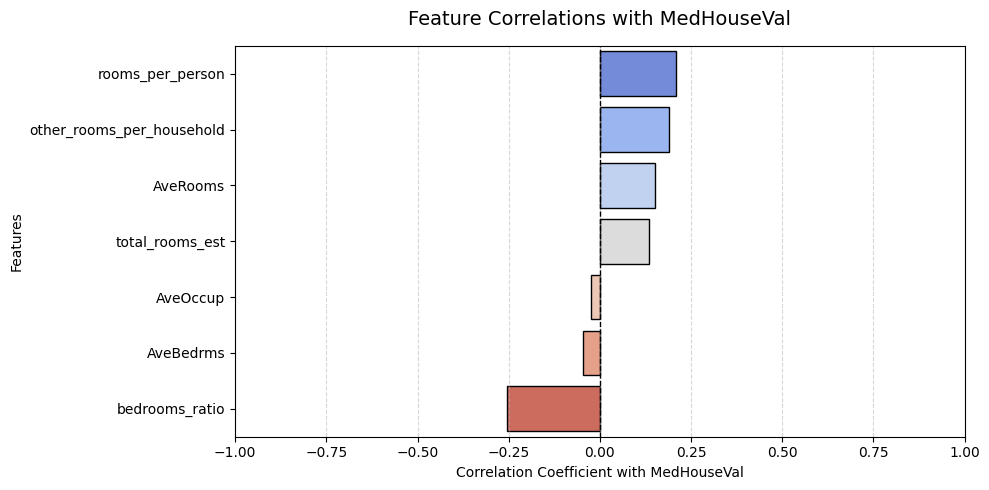

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define features (excluding target)
features = ["AveRooms", "AveBedrms", "AveOccup",
            "bedrooms_ratio", "rooms_per_person",
            "other_rooms_per_household", "total_rooms_est"]

# 2. Calculate correlation of all features specifically with the target
correlations = housing[features].corrwith(housing[target]).sort_values(ascending=False)

# 3. Plot
plt.figure(figsize=(10, 5))
sns.barplot(x=correlations.values, y=correlations.index, palette="coolwarm", edgecolor="black")

# Add a vertical line at 0 for baseline reference
plt.axvline(x=0, color="black", linestyle="--", linewidth=1)

plt.xlabel(f"Correlation Coefficient with {target}")
plt.ylabel("Features")
plt.title(f"Feature Correlations with {target}", fontsize=14, pad=15)
plt.xlim(-1, 1)  # Correlation bounds
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


## Questions
* ### Derive some more ratio and difference based features 
* ### See the correlation with the target
* ### Check Correlation of all features. Identify some of the features that are redundant using correlation analysis. 


In [35]:
rooms = housing["AveRooms"].replace(0, np.nan)
bedrooms = housing["AveBedrms"].replace(0, np.nan)
occupancy = housing["AveOccup"].replace(0, np.nan)

# Ratio features: measures of crowding and available space
housing["occupants_per_room"] = housing["AveOccup"] / rooms
housing["occupants_per_bedroom"] = housing["AveOccup"] / bedrooms
housing["non_bedrooms_per_person"] = (
    housing["AveRooms"] - housing["AveBedrms"]
) / occupancy

# Difference features: deviations from typical values in the dataset
housing["house_age_above_median"] = (
    housing["HouseAge"] - housing["HouseAge"].median()
)
housing["rooms_above_median"] = (
    housing["AveRooms"] - housing["AveRooms"].median()
)

new_features = [
    "occupants_per_room",
    "occupants_per_bedroom",
    "non_bedrooms_per_person",
    "house_age_above_median",
    "rooms_above_median",
]

display(housing[new_features].head(10))

,occupants_per_room,occupants_per_bedroom,non_bedrooms_per_person,house_age_above_median,rooms_above_median
0,0.365909,2.496124,2.332298,12.0,1.754998
1,0.338217,2.170886,2.496043,-8.0,1.009008
2,0.338105,2.610526,2.574597,23.0,3.059007
3,0.437991,2.374468,1.862007,23.0,0.588223
4,0.347265,2.017857,2.384071,23.0,1.052724
5,0.449402,1.938967,1.709443,23.0,-0.467471
6,0.431558,2.237219,1.870201,23.0,-0.297222
7,0.372745,1.684134,2.089023,23.0,-0.431602
8,0.472016,1.813534,1.567164,13.0,-0.935011
9,0.437025,2.193777,1.832366,23.0,-0.258541


Correlation with MedHouseVal:
non_bedrooms_per_person    0.239
rooms_above_median         0.152
house_age_above_median     0.106
occupants_per_room        -0.034
occupants_per_bedroom     -0.019
dtype: float64


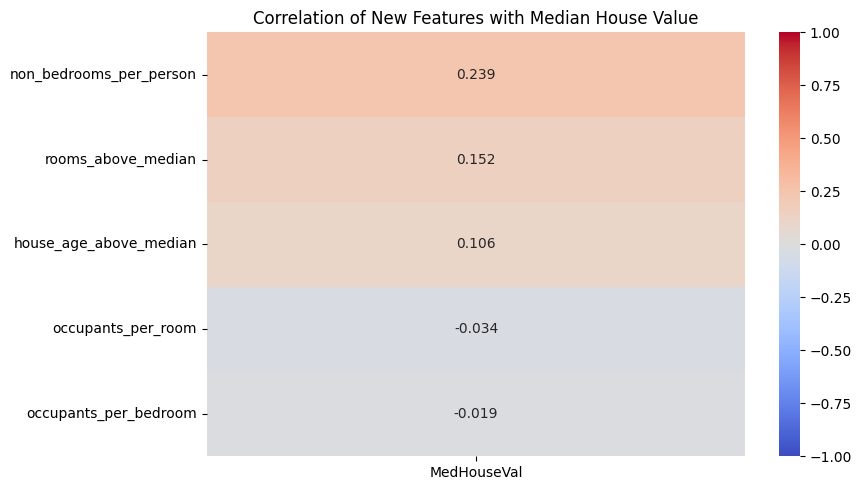

In [36]:
new_features = [
    "occupants_per_room",
    "occupants_per_bedroom",
    "non_bedrooms_per_person",
    "house_age_above_median",
    "rooms_above_median",
]

correlations = (
    housing[new_features]
    .corrwith(housing["MedHouseVal"])
    .sort_values(key=abs, ascending=False)
)

print("Correlation with MedHouseVal:")
print(correlations.round(3))

plt.figure(figsize=(9, 5))
sns.heatmap(
    correlations.to_frame("MedHouseVal"),
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)
plt.title("Correlation of New Features with Median House Value")
plt.tight_layout()
plt.show()

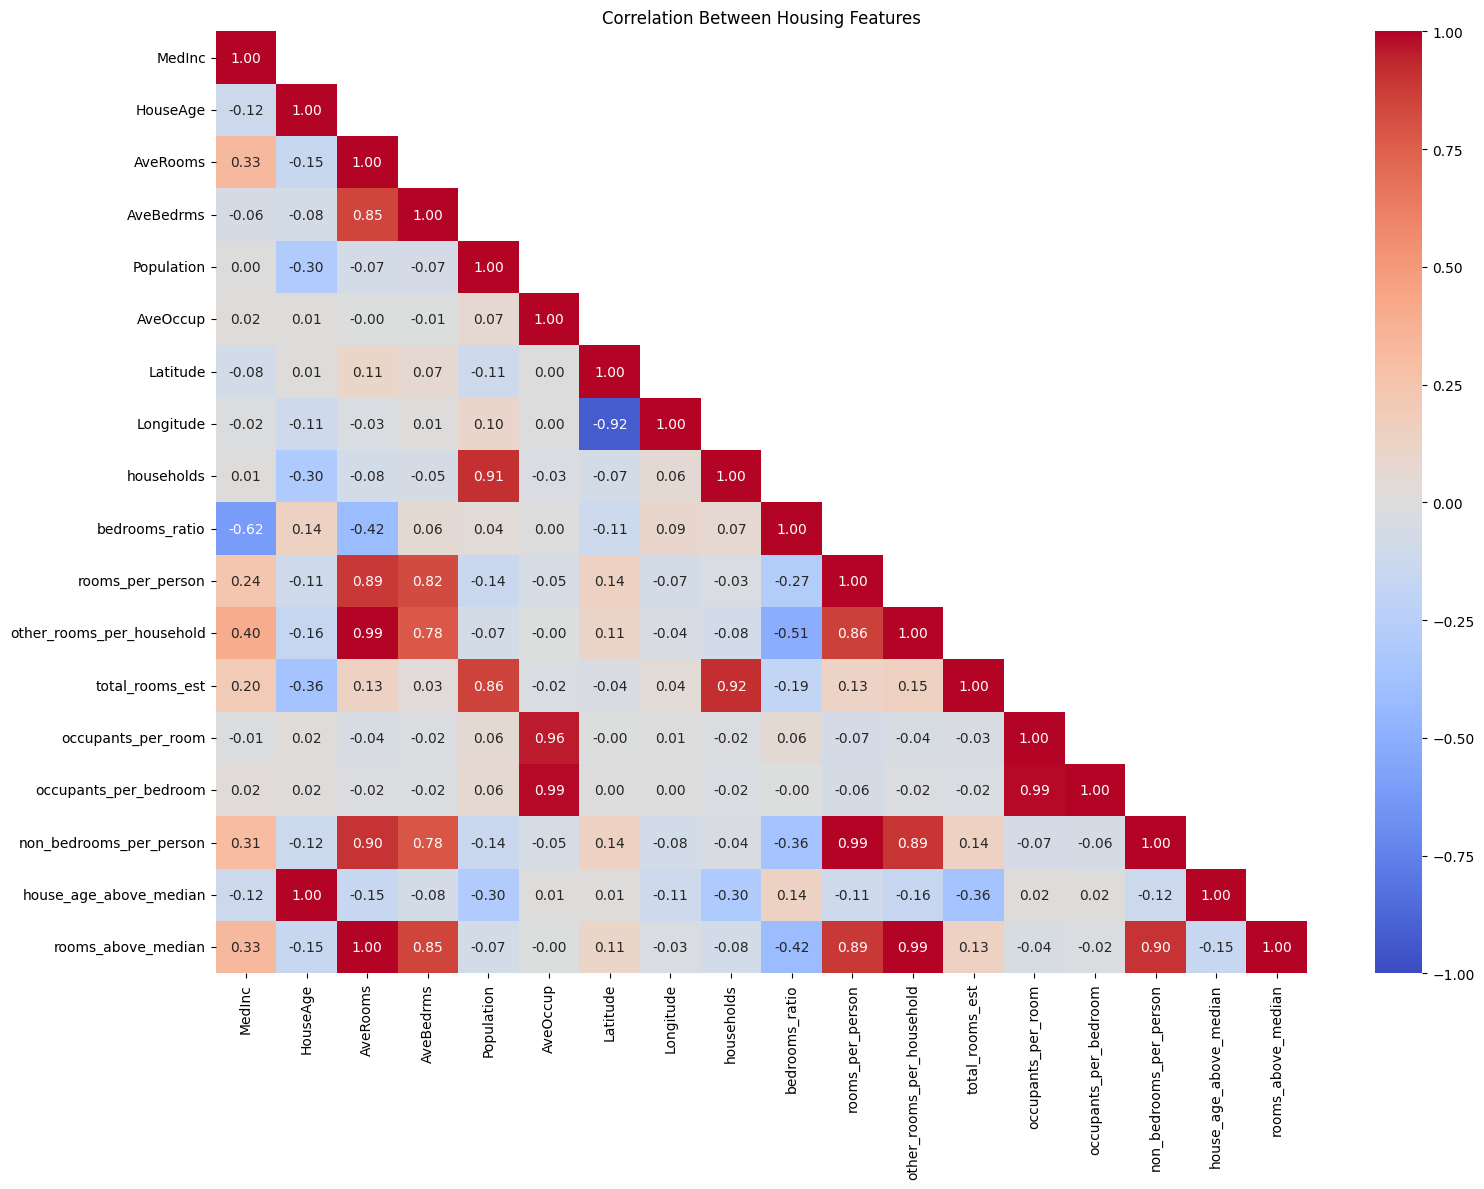

Potentially redundant pairs (|correlation| >= 0.9):
                Feature 1                 Feature 2  Correlation
                 HouseAge    house_age_above_median        1.000
                 AveRooms        rooms_above_median        1.000
         rooms_per_person   non_bedrooms_per_person        0.994
other_rooms_per_household        rooms_above_median        0.993
                 AveRooms other_rooms_per_household        0.993
       occupants_per_room     occupants_per_bedroom        0.991
                 AveOccup     occupants_per_bedroom        0.986
                 AveOccup        occupants_per_room        0.960
                 Latitude                 Longitude       -0.925
               households           total_rooms_est        0.918
               Population                households        0.907
  non_bedrooms_per_person        rooms_above_median        0.905
                 AveRooms   non_bedrooms_per_person        0.905


In [37]:
features = housing.select_dtypes(include="number").drop(
    columns=["MedHouseVal"], errors="ignore"
)

corr = features.corr()

# Plot the correlation matrix
plt.figure(figsize=(16, 12))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    mask=np.triu(np.ones(corr.shape, dtype=bool), k=1),
)
plt.title("Correlation Between Housing Features")
plt.tight_layout()
plt.show()

# Inspect each pair once, excluding self-correlations
upper = corr.where(
    np.triu(np.ones(corr.shape, dtype=bool), k=1)
)

pairs = (
    upper.stack()
    .rename("Correlation")
    .reset_index()
)
pairs.columns = ["Feature 1", "Feature 2", "Correlation"]

threshold = 0.90
redundant_pairs = pairs[
    pairs["Correlation"].abs() >= threshold
].copy()

redundant_pairs = redundant_pairs.sort_values(
    "Correlation", key=abs, ascending=False
)

print(f"Potentially redundant pairs (|correlation| >= {threshold}):")
print(redundant_pairs.round(3).to_string(index=False))

# Aggregation based features

**Dataset description: IRIS dataset**

Fisher's classic 1936 flower measurements: 150 samples, 3 species, 4 numeric columns (sepal/petal length & width). 

Target is species — discrete/categorical, 3 balanced classes (50 each). 

Used here for unsupervised-flavored meta-features (density, PCA, centroid distance) rather than direct classification.


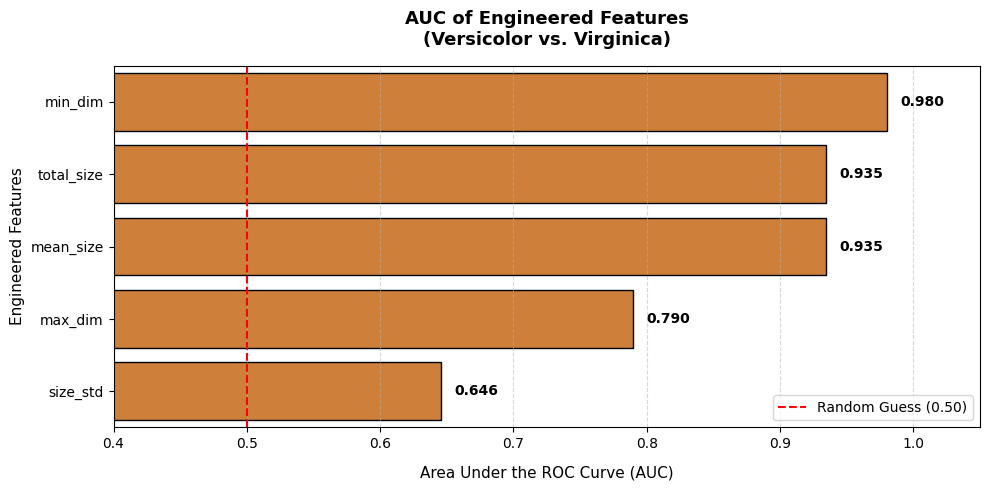

In [38]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

# 1. Load data and engineer features
iris = sns.load_dataset("iris")
measurement_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

iris["total_size"] = iris[measurement_cols].sum(axis=1)
iris["mean_size"]  = iris[measurement_cols].mean(axis=1)
iris["size_std"]   = iris[measurement_cols].std(axis=1)
iris["min_dim"]    = iris[measurement_cols].min(axis=1)
iris["max_dim"]    = iris[measurement_cols].max(axis=1)


# 2. Filter dataset for binary classification (Versicolor vs. Virginica)
binary_iris = iris[iris["species"].isin(["versicolor", "virginica"])].copy()
y_true = (binary_iris["species"] == "virginica").astype(int)

# 3. Compute Absolute AUC for only the engineered features
engineered_features = ["total_size", "mean_size", "size_std", "min_dim", "max_dim"]
auc_data = []

for col in engineered_features:
    auc = roc_auc_score(y_true, binary_iris[col])
    absolute_auc = max(auc, 1 - auc)  # Correct for negative correlation
    auc_data.append({"Feature": col, "AUC": absolute_auc})

# Convert to DataFrame and sort descending
df_auc = pd.DataFrame(auc_data).sort_values(by="AUC", ascending=False)

# 4. Plot using Seaborn
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=df_auc, 
    x="AUC", 
    y="Feature", 
    color="#e67e22",  # Professional orange representing engineered features
    edgecolor="black"
)

# Draw a vertical dashed line at 0.5 (Random Guessing baseline)
plt.axvline(x=0.5, color="red", linestyle="--", linewidth=1.5, label="Random Guess (0.50)")

# Annotate each bar with its exact AUC value
for bar in ax.patches:
    width = bar.get_width()
    if width > 0:
        ax.text(
            width + 0.01, 
            bar.get_y() + bar.get_height() / 2, 
            f"{width:.3f}", 
            va="center", 
            ha="left", 
            fontsize=10, 
            fontweight="semibold"
        )

# Customize plot details
plt.xlim(0.4, 1.05)  # Focus on the area above 0.50
plt.xlabel("Area Under the ROC Curve (AUC)", fontsize=11, labelpad=10)
plt.ylabel("Engineered Features", fontsize=11)
plt.title("AUC of Engineered Features\n(Versicolor vs. Virginica)", fontsize=13, pad=15, fontweight="bold")
plt.legend(loc="lower right")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


## Questions:
### Plot the AUC of all the features. What are some of the most important and least important features. 
### Create a feature which is a product/division of two best features. Does it improve the AUC?
### Create a feature such as "by how much I am above/below average of a particular column" for e.g. in percentage
 

     Feature  Raw AUC   AUC
petal_length    0.982 0.982
     min_dim    0.980 0.980
 petal_width    0.980 0.980
   mean_size    0.935 0.935
  total_size    0.935 0.935
sepal_length    0.790 0.790
     max_dim    0.790 0.790
 sepal_width    0.664 0.664
    size_std    0.646 0.646


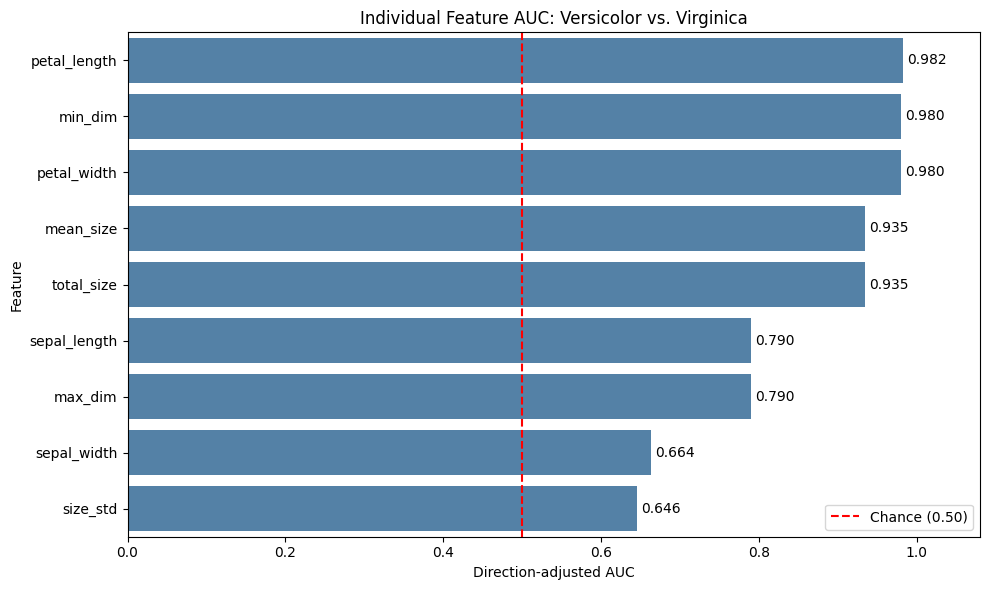


Most predictive features:
     Feature    AUC
petal_length 0.9822
     min_dim 0.9804
 petal_width 0.9804

Least predictive features:
    Feature    AUC
    max_dim 0.7896
sepal_width 0.6636
   size_std 0.6458


In [39]:
# Binary classification: virginica = 1, versicolor = 0
binary_iris = iris[
    iris["species"].isin(["versicolor", "virginica"])
].copy()

y_true = (binary_iris["species"] == "virginica").astype(int)

features = binary_iris.select_dtypes(include="number").columns

results = []

for feature in features:
    valid = binary_iris[feature].notna()
    auc = roc_auc_score(
        y_true[valid],
        binary_iris.loc[valid, feature],
    )

    results.append({
        "Feature": feature,
        "Raw AUC": auc,
        "AUC": max(auc, 1 - auc),
    })

auc_results = (
    pd.DataFrame(results)
    .sort_values("AUC", ascending=False)
    .reset_index(drop=True)
)

print(auc_results.round(3).to_string(index=False))

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=auc_results,
    x="AUC",
    y="Feature",
    color="steelblue",
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.axvline(
    0.5, color="red", linestyle="--", label="Chance (0.50)"
)
plt.xlim(0, 1.08)
plt.xlabel("Direction-adjusted AUC")
plt.ylabel("Feature")
plt.title("Individual Feature AUC: Versicolor vs. Virginica")
plt.legend()
plt.tight_layout()
plt.show()

print("\nMost predictive features:")
print(auc_results.head(3)[["Feature", "AUC"]].to_string(index=False))

print("\nLeast predictive features:")
print(auc_results.tail(3)[["Feature", "AUC"]].to_string(index=False))

Selected features: petal_length and min_dim

AUC comparison:
     Feature    AUC
petal_length 0.9822
     min_dim 0.9804
best_product 0.9944
  best_ratio 0.8202

best_product: change in AUC = +0.0122

best_ratio: change in AUC = -0.1620


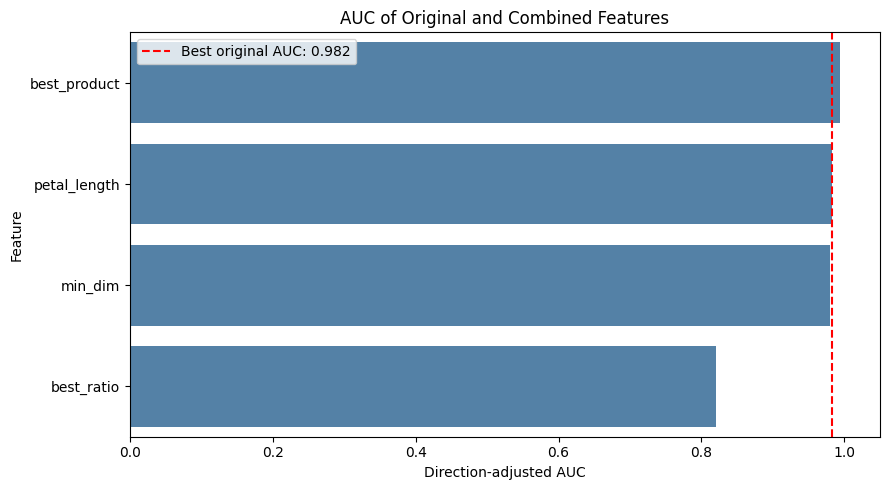

In [40]:
# Get the two best features from Q1
best_features = auc_results.nlargest(2, "AUC")["Feature"].tolist()
feature_1, feature_2 = best_features

print(f"Selected features: {feature_1} and {feature_2}")

# Create product and ratio features
binary_iris["best_product"] = (
    binary_iris[feature_1] * binary_iris[feature_2]
)

binary_iris["best_ratio"] = (
    binary_iris[feature_1]
    / binary_iris[feature_2].replace(0, np.nan)
)

features_to_compare = [
    feature_1,
    feature_2,
    "best_product",
    "best_ratio",
]

# Use the same rows for every comparison
comparison = (
    binary_iris[features_to_compare + ["species"]]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

y = (comparison["species"] == "virginica").astype(int)

results = []

for feature in features_to_compare:
    auc = roc_auc_score(y, comparison[feature])
    results.append({
        "Feature": feature,
        "AUC": max(auc, 1 - auc),
    })

comparison_auc = pd.DataFrame(results)

print("\nAUC comparison:")
print(comparison_auc.round(4).to_string(index=False))

# Compare each new feature with the best original feature
baseline = comparison_auc.iloc[:2]["AUC"].max()

for feature in ["best_product", "best_ratio"]:
    score = comparison_auc.loc[
        comparison_auc["Feature"] == feature, "AUC"
    ].iloc[0]

    change = score - baseline
    print(f"\n{feature}: change in AUC = {change:+.4f}")

# Plot results
plt.figure(figsize=(9, 5))
sns.barplot(
    data=comparison_auc.sort_values("AUC", ascending=False),
    x="AUC",
    y="Feature",
    color="steelblue",
)
plt.axvline(
    baseline,
    color="red",
    linestyle="--",
    label=f"Best original AUC: {baseline:.3f}",
)
plt.xlim(0, 1.05)
plt.title("AUC of Original and Combined Features")
plt.xlabel("Direction-adjusted AUC")
plt.legend()
plt.tight_layout()
plt.show()

       species  petal_length  petal_length_pct_from_mean
50  versicolor           4.7                   -4.198940
51  versicolor           4.5                   -8.275581
52  versicolor           4.9                   -0.122299
53  versicolor           4.0                  -18.467183
54  versicolor           4.6                   -6.237260
55  versicolor           4.5                   -8.275581
56  versicolor           4.7                   -4.198940
57  versicolor           3.3                  -32.735426
58  versicolor           4.6                   -6.237260
59  versicolor           3.9                  -20.505503


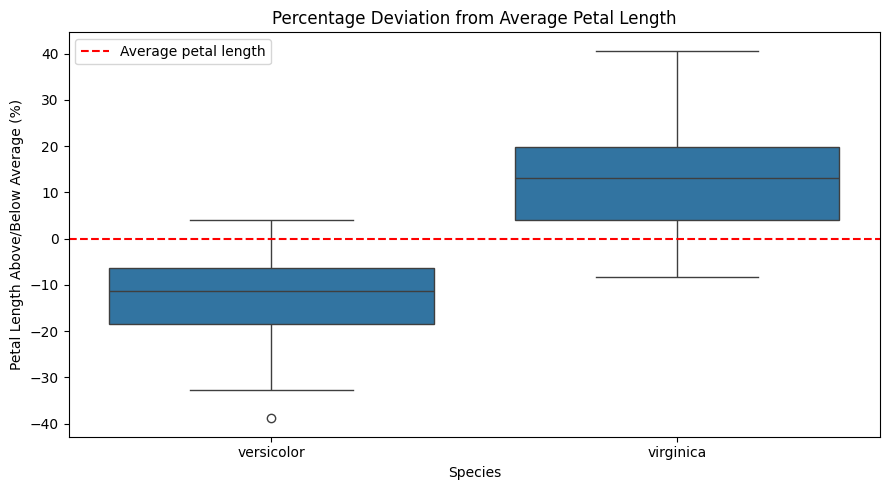

Direction-adjusted AUC: 0.982


In [41]:
# Calculate the average across the two species being compared
mean_petal_length = binary_iris["petal_length"].mean()

binary_iris["petal_length_pct_from_mean"] = (
    (binary_iris["petal_length"] - mean_petal_length)
    / mean_petal_length
    * 100
)

print(
    binary_iris[
        ["species", "petal_length", "petal_length_pct_from_mean"]
    ].head(10)
)

# Plot the feature by species
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=binary_iris,
    x="species",
    y="petal_length_pct_from_mean",
)
plt.axhline(0, color="red", linestyle="--", label="Average petal length")
plt.ylabel("Petal Length Above/Below Average (%)")
plt.xlabel("Species")
plt.title("Percentage Deviation from Average Petal Length")
plt.legend()
plt.tight_layout()
plt.show()

# Calculate direction-adjusted AUC
y = (binary_iris["species"] == "virginica").astype(int)
auc = roc_auc_score(y, binary_iris["petal_length_pct_from_mean"])

print(f"Direction-adjusted AUC: {max(auc, 1 - auc):.3f}")

# Likelihood / density-based features

In [ ]:
from sklearn.mixture import GaussianMixture
import seaborn as sns
iris = sns.load_dataset("iris")
measurement_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

X = iris[measurement_cols].values
gmm = GaussianMixture(n_components=3, random_state=0).fit(X)
iris["log_likelihood"] = gmm.score_samples(X)

display(iris[["species", "log_likelihood"]].sort_values("log_likelihood").head(10))  # most atypical flowers
print(iris.groupby("species")["log_likelihood"].mean())


Training GMMs per class

Using log likelihood as features 

Train test splits to check the AUC (discriminatory power) of each feature. 

In [ ]:
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.mixture import GaussianMixture
from sklearn.metrics import roc_auc_score

# 1. Load data
iris = sns.load_dataset("iris")
measurement_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

# Keep only Versicolor and Virginica
binary_iris = iris[iris["species"].isin(["versicolor", "virginica"])].copy()

# 2. Extract subsets for GMM training
versicolor_data = binary_iris[binary_iris["species"] == "versicolor"][measurement_cols].values
virginica_data = binary_iris[binary_iris["species"] == "virginica"][measurement_cols].values

# 3. Fit one GMM per class (e.g., 1 component each for a single Gaussian, or 2 components)
# Let's use 1 component for simplicity, which is equivalent to a Gaussian QDA classifier
gmm_versicolor = GaussianMixture(n_components=1, random_state=0).fit(versicolor_data)
gmm_virginica  = GaussianMixture(n_components=1, random_state=0).fit(virginica_data)

# 4. Compute log-likelihood of all binary_iris samples under BOTH models
X_all = binary_iris[measurement_cols].values
binary_iris["log_lik_versicolor"] = gmm_versicolor.score_samples(X_all)
binary_iris["log_lik_virginica"]  = gmm_virginica.score_samples(X_all)

# 5. The engineered classifier feature is the difference (log-likelihood ratio)
binary_iris["log_lik_diff"] = binary_iris["log_lik_virginica"] - binary_iris["log_lik_versicolor"]

# 6. Compute AUC
y_true = (binary_iris["species"] == "virginica").astype(int)
auc = roc_auc_score(y_true, binary_iris["log_lik_diff"])

print("--- Class-Specific GMM Feature Engineering ---")
print(f"Log-Likelihood Difference (Virginica - Versicolor) AUC: {auc:.4f}")


## Questions

### Try to see the effect of increasing the number of Gaussian components on AUC 
### Try to use PCA on the measurment_cols and use the output as additional feature. 
### Compare the performance in terms of AUC with the GMM likelihood based feature


 Components  Train AUC  Test AUC
          1     0.9992    1.0000
          2     0.9984    0.9911
          3     1.0000    0.9378
          4     1.0000    0.9511
          5     1.0000    0.9244
          6     1.0000    0.9156
          7     1.0000    0.9244
          8     1.0000    0.8933
          9     1.0000    0.8889
         10     1.0000    0.8178


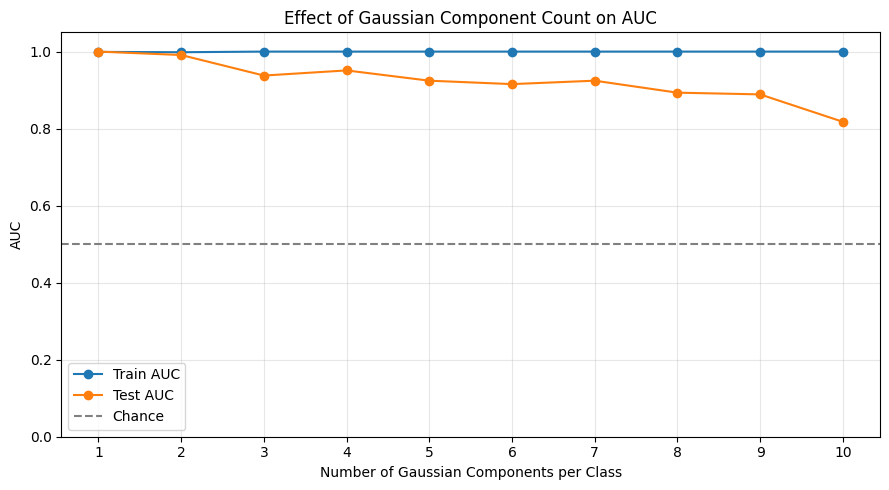

In [42]:
from sklearn.model_selection import train_test_split
from sklearn.mixture import GaussianMixture
from sklearn.metrics import roc_auc_score

measurement_cols = [
    "sepal_length", "sepal_width", "petal_length", "petal_width"
]

binary_iris = iris[
    iris["species"].isin(["versicolor", "virginica"])
].copy()

X = binary_iris[measurement_cols]
y = (binary_iris["species"] == "virginica").astype(int)

# Keep the split fixed for every component count
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    stratify=y,
    random_state=42,
)

results = []

for n in range(1, 11):
    # Fit one GMM per species using training data only
    gmm_versicolor = GaussianMixture(
        n_components=n,
        covariance_type="full",
        n_init=5,
        reg_covar=1e-6,
        random_state=42,
    ).fit(X_train.loc[y_train == 0])

    gmm_virginica = GaussianMixture(
        n_components=n,
        covariance_type="full",
        n_init=5,
        reg_covar=1e-6,
        random_state=42,
    ).fit(X_train.loc[y_train == 1])

    # Higher scores indicate stronger evidence for virginica
    train_scores = (
        gmm_virginica.score_samples(X_train)
        - gmm_versicolor.score_samples(X_train)
    )
    test_scores = (
        gmm_virginica.score_samples(X_test)
        - gmm_versicolor.score_samples(X_test)
    )

    results.append({
        "Components": n,
        "Train AUC": roc_auc_score(y_train, train_scores),
        "Test AUC": roc_auc_score(y_test, test_scores),
    })

auc_results = pd.DataFrame(results)
print(auc_results.round(4).to_string(index=False))

plt.figure(figsize=(9, 5))
plt.plot(
    auc_results["Components"], auc_results["Train AUC"],
    marker="o", label="Train AUC",
)
plt.plot(
    auc_results["Components"], auc_results["Test AUC"],
    marker="o", label="Test AUC",
)
plt.axhline(0.5, color="grey", linestyle="--", label="Chance")
plt.xticks(range(1, 11))
plt.ylim(0, 1.05)
plt.xlabel("Number of Gaussian Components per Class")
plt.ylabel("AUC")
plt.title("Effect of Gaussian Component Count on AUC")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [43]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Standardise measurements so each has comparable influence on PCA
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train[measurement_cols])
X_test_scaled = scaler.transform(X_test[measurement_cols])

# Fit PCA on training data and transform both sets
pca = PCA(n_components=2)

train_components = pca.fit_transform(X_train_scaled)
test_components = pca.transform(X_test_scaled)

# Add the PCA features alongside the original measurements
X_train_with_pca = X_train[measurement_cols].copy()
X_test_with_pca = X_test[measurement_cols].copy()

X_train_with_pca[["PC1", "PC2"]] = train_components
X_test_with_pca[["PC1", "PC2"]] = test_components

print("Training data with PCA features:")
display(X_train_with_pca.head())

print("Explained variance:")
for name, ratio in zip(["PC1", "PC2"], pca.explained_variance_ratio_):
    print(f"{name}: {ratio:.2%}")

print(
    f"Total variance retained: "
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

Training data with PCA features:


,sepal_length,sepal_width,petal_length,petal_width,PC1,PC2
136,6.3,3.4,5.6,2.4,1.914577,0.929379
104,6.5,3.0,5.8,2.2,1.420302,-0.333317
102,7.1,3.0,5.9,2.1,1.855445,-0.681137
115,6.4,3.2,5.3,2.3,1.392828,0.467741
126,6.2,2.8,4.8,1.8,-0.244186,-0.227865


Explained variance:
PC1: 74.02%
PC2: 12.95%
Total variance retained: 86.97%


                      Feature  Test AUC
GMM log-likelihood difference    1.0000
                          PC1    0.8756
                          PC2    0.7867


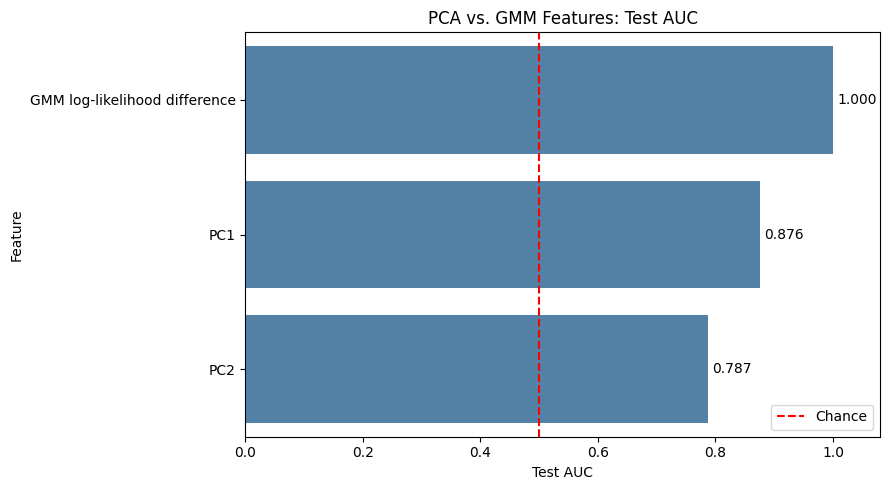

In [44]:
# Fit one Gaussian per class using training measurements only
gmm_versicolor = GaussianMixture(
    n_components=1, random_state=42
).fit(X_train.loc[y_train == 0, measurement_cols])

gmm_virginica = GaussianMixture(
    n_components=1, random_state=42
).fit(X_train.loc[y_train == 1, measurement_cols])

# GMM score: higher values favour virginica
gmm_test_scores = (
    gmm_virginica.score_samples(X_test[measurement_cols])
    - gmm_versicolor.score_samples(X_test[measurement_cols])
)

results = []

# Evaluate each PCA feature individually
for feature in ["PC1", "PC2"]:
    train_scores = X_train_with_pca[feature]
    test_scores = X_test_with_pca[feature]

    # Determine score direction using training labels only
    direction = (
        1 if roc_auc_score(y_train, train_scores) >= 0.5 else -1
    )

    results.append({
        "Feature": feature,
        "Test AUC": roc_auc_score(y_test, direction * test_scores),
    })

results.append({
    "Feature": "GMM log-likelihood difference",
    "Test AUC": roc_auc_score(y_test, gmm_test_scores),
})

comparison = pd.DataFrame(results).sort_values(
    "Test AUC", ascending=False
)

print(comparison.round(4).to_string(index=False))

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=comparison,
    x="Test AUC",
    y="Feature",
    color="steelblue",
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.axvline(0.5, color="red", linestyle="--", label="Chance")
plt.xlim(0, 1.08)
plt.title("PCA vs. GMM Features: Test AUC")
plt.legend()
plt.tight_layout()
plt.show()

In [46]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.mixture import GaussianMixture
from sklearn.metrics import roc_auc_score

# 1. Load Iris data and filter to Versicolor and Virginica
iris = sns.load_dataset("iris")
measurement_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
binary_iris = iris[iris["species"].isin(["versicolor", "virginica"])].copy()

# 2. Train-Test Split (Crucial step to prevent leakage and contamination)
# Stratifying ensures we keep a 50/50 balance of classes in both train and test splits
train_df, test_df = train_test_split(
    binary_iris, 
    test_size=0.4, 
    random_state=3, 
    stratify=binary_iris["species"]
)

# 3. Partition ONLY the training set by class to train our GMMs
X_train_versicolor = train_df[train_df["species"] == "versicolor"][measurement_cols].values
X_train_virginica  = train_df[train_df["species"] == "virginica"][measurement_cols].values

# Fit GMMs on respective training slices
gmm_versicolor = GaussianMixture(n_components=1, random_state=0).fit(X_train_versicolor)
gmm_virginica  = GaussianMixture(n_components=1, random_state=0).fit(X_train_virginica)

# 4. Generate engineered features ONLY on the unseen Test Set
X_test = test_df[measurement_cols].values
test_df["log_lik_versicolor"] = gmm_versicolor.score_samples(X_test)
test_df["log_lik_virginica"]  = gmm_virginica.score_samples(X_test)

# Compute the log-likelihood difference (our classification score)
test_df["log_lik_diff"] = test_df["log_lik_virginica"] - test_df["log_lik_versicolor"]

# 5. Evaluate the AUC on the unseen Test Set
y_test_true = (test_df["species"] == "virginica").astype(int)
auc_test = roc_auc_score(y_test_true, test_df["log_lik_diff"])

print("--- Leak-Proof Class-Specific GMM ---")
print(f"Total Binary Samples: {len(binary_iris)}")
print(f"Training Samples:     {len(train_df)}  (Versicolor: {sum(train_df['species']=='versicolor')}, Virginica: {sum(train_df['species']=='virginica')})")
print(f"Test Samples:         {len(test_df)}   (Versicolor: {sum(test_df['species']=='versicolor')}, Virginica: {sum(test_df['species']=='virginica')})")
print(f"------------------------------------")
print(f"Unseen Test Set AUC:  {auc_test:.4f}")


--- Leak-Proof Class-Specific GMM ---
Total Binary Samples: 100
Training Samples:     60  (Versicolor: 30, Virginica: 30)
Test Samples:         40   (Versicolor: 20, Virginica: 20)
------------------------------------
Unseen Test Set AUC:  0.9875


## Questions
* ### Whats your observations if we dont do the train test split (as in the cell above). Train GMMs on whole dataset and then get the likelihood for each sample. Now calculate the AUC of the likelihood features. 
* ### Check the effect of random state in train/test split function on the test AUC. What does it tell you
* ### See the effect on the AUC when you increase number of Gaussians
* ### Try different covariance types in the Gaussian mixtures


In [50]:
full_data = binary_iris.copy()
X_all = full_data[measurement_cols]
y_all = (full_data["species"] == "virginica").astype(int)

# Fit each GMM on all available samples of its class
gmm_versicolor_full = GaussianMixture(
    n_components=1, random_state=0
).fit(X_all.loc[y_all == 0])

gmm_virginica_full = GaussianMixture(
    n_components=1, random_state=0
).fit(X_all.loc[y_all == 1])

# Calculate likelihood features for every sample
full_data["log_lik_versicolor"] = (
    gmm_versicolor_full.score_samples(X_all)
)
full_data["log_lik_virginica"] = (
    gmm_virginica_full.score_samples(X_all)
)
full_data["log_lik_diff"] = (
    full_data["log_lik_virginica"]
    - full_data["log_lik_versicolor"]
)

# Calculate AUC for each feature
results = []

for feature in [
    "log_lik_versicolor",
    "log_lik_virginica",
    "log_lik_diff",
]:
    auc = roc_auc_score(y_all, full_data[feature])

    results.append({
        "Feature": feature,
        "Raw AUC": auc,
        "Direction-adjusted AUC": max(auc, 1 - auc),
    })

print(pd.DataFrame(results).round(4).to_string(index=False))

# Compare the likelihood difference with cell 51's test AUC
full_auc = roc_auc_score(y_all, full_data["log_lik_diff"])

print(f"\nFull-data evaluation AUC: {full_auc:.4f}")
print(f"Unseen test AUC:  {auc_test:.4f}")

           Feature  Raw AUC  Direction-adjusted AUC
log_lik_versicolor   0.0116                  0.9884
 log_lik_virginica   0.9656                  0.9656
      log_lik_diff   0.9992                  0.9992

Full-data evaluation AUC: 0.9992
Unseen test AUC:  0.9875


 Split random state  Test AUC
                  0    1.0000
                  1    0.9950
                  2    1.0000
                  3    0.9875
                  4    1.0000
                  5    1.0000
                  6    0.9950
                  7    1.0000
                  8    0.9950
                  9    0.9925
                 10    1.0000
                 11    0.9925
                 12    0.9900
                 13    0.9975
                 14    1.0000
                 15    1.0000
                 16    1.0000
                 17    0.9950
                 18    1.0000
                 19    0.9875
                 20    0.9950
                 21    0.9875
                 22    1.0000
                 23    1.0000
                 24    0.9975
                 25    1.0000
                 26    1.0000
                 27    0.9975
                 28    1.0000
                 29    0.9900

AUC summary:
mean    0.9965
std     0.0044
min     0.9875
max     1.0

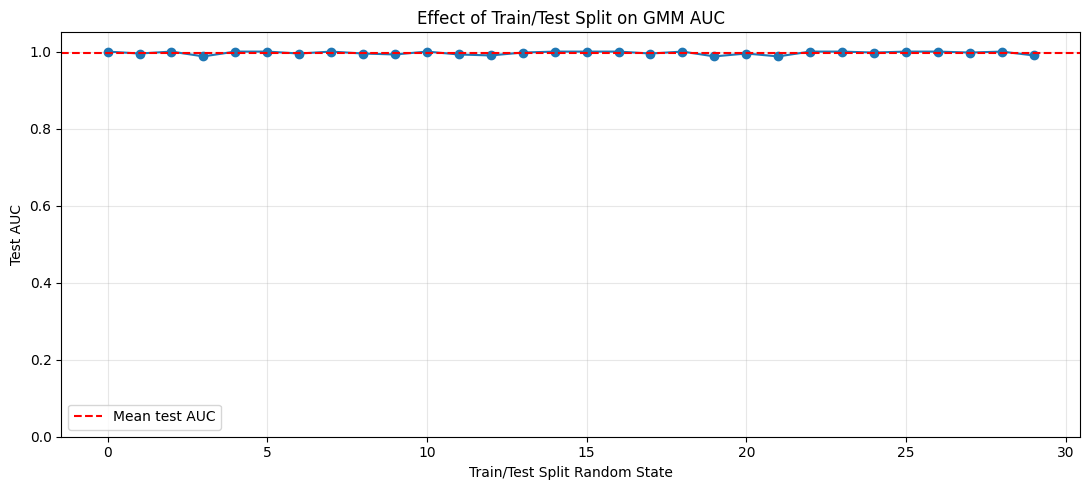

In [48]:
results = []

for split_seed in range(30):
    train_df, test_df = train_test_split(
        binary_iris,
        test_size=0.4,
        random_state=split_seed,
        stratify=binary_iris["species"],
    )

    # Keep GMM settings fixed across splits
    gmm_versicolor = GaussianMixture(
        n_components=1,
        random_state=0,
    ).fit(
        train_df.loc[
            train_df["species"] == "versicolor", measurement_cols
        ]
    )

    gmm_virginica = GaussianMixture(
        n_components=1,
        random_state=0,
    ).fit(
        train_df.loc[
            train_df["species"] == "virginica", measurement_cols
        ]
    )

    X_test = test_df[measurement_cols]
    y_test = (test_df["species"] == "virginica").astype(int)

    test_scores = (
        gmm_virginica.score_samples(X_test)
        - gmm_versicolor.score_samples(X_test)
    )

    results.append({
        "Split random state": split_seed,
        "Test AUC": roc_auc_score(y_test, test_scores),
    })

split_results = pd.DataFrame(results)

print(split_results.round(4).to_string(index=False))
print("\nAUC summary:")
print(
    split_results["Test AUC"]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)

plt.figure(figsize=(11, 5))
plt.plot(
    split_results["Split random state"],
    split_results["Test AUC"],
    marker="o",
)
plt.axhline(
    split_results["Test AUC"].mean(),
    color="red",
    linestyle="--",
    label="Mean test AUC",
)
plt.xlabel("Train/Test Split Random State")
plt.ylabel("Test AUC")
plt.title("Effect of Train/Test Split on GMM AUC")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

 Components per class  Train AUC  Test AUC
                    1        1.0    0.9875
                    2        1.0    0.9850
                    3        1.0    0.9825
                    4        1.0    0.9800
                    5        1.0    0.9250
                    6        1.0    0.8725
                    7        1.0    0.9675
                    8        1.0    0.6375
                    9        1.0    0.6400
                   10        1.0    0.6275


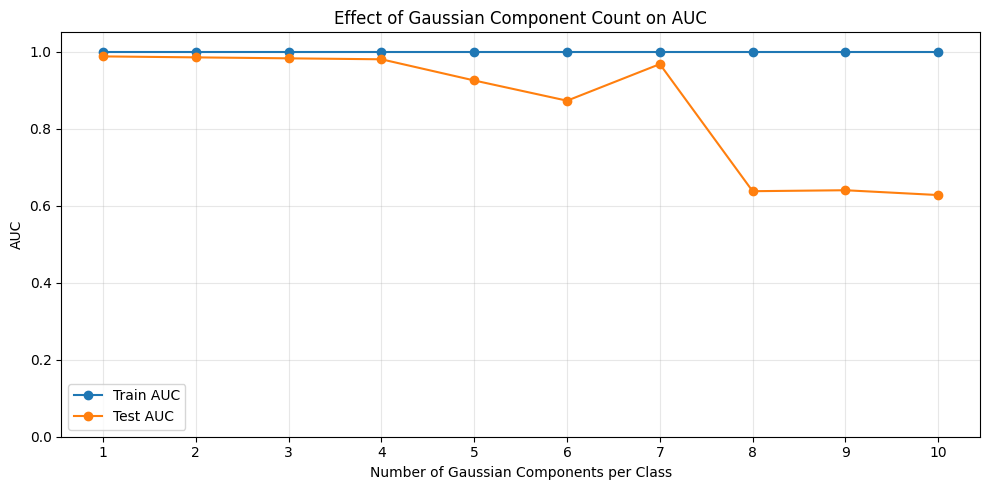

In [49]:
train_df, test_df = train_test_split(
    binary_iris,
    test_size=0.4,
    random_state=3,
    stratify=binary_iris["species"],
)

X_train = train_df[measurement_cols]
X_test = test_df[measurement_cols]

y_train = (train_df["species"] == "virginica").astype(int)
y_test = (test_df["species"] == "virginica").astype(int)

results = []

for n in range(1, 11):
    gmm_versicolor = GaussianMixture(
        n_components=n,
        covariance_type="full",
        n_init=5,
        reg_covar=1e-6,
        random_state=0,
    ).fit(X_train.loc[y_train == 0])

    gmm_virginica = GaussianMixture(
        n_components=n,
        covariance_type="full",
        n_init=5,
        reg_covar=1e-6,
        random_state=0,
    ).fit(X_train.loc[y_train == 1])

    train_scores = (
        gmm_virginica.score_samples(X_train)
        - gmm_versicolor.score_samples(X_train)
    )
    test_scores = (
        gmm_virginica.score_samples(X_test)
        - gmm_versicolor.score_samples(X_test)
    )

    results.append({
        "Components per class": n,
        "Train AUC": roc_auc_score(y_train, train_scores),
        "Test AUC": roc_auc_score(y_test, test_scores),
    })

component_results = pd.DataFrame(results)
print(component_results.round(4).to_string(index=False))

plt.figure(figsize=(10, 5))
plt.plot(
    component_results["Components per class"],
    component_results["Train AUC"],
    marker="o",
    label="Train AUC",
)
plt.plot(
    component_results["Components per class"],
    component_results["Test AUC"],
    marker="o",
    label="Test AUC",
)
plt.xticks(range(1, 11))
plt.ylim(0, 1.05)
plt.xlabel("Number of Gaussian Components per Class")
plt.ylabel("AUC")
plt.title("Effect of Gaussian Component Count on AUC")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Covariance type  Train AUC  Test AUC
           full     1.0000    0.9850
           tied     1.0000    0.9875
           diag     0.9978    0.9925
      spherical     0.9989    0.9925


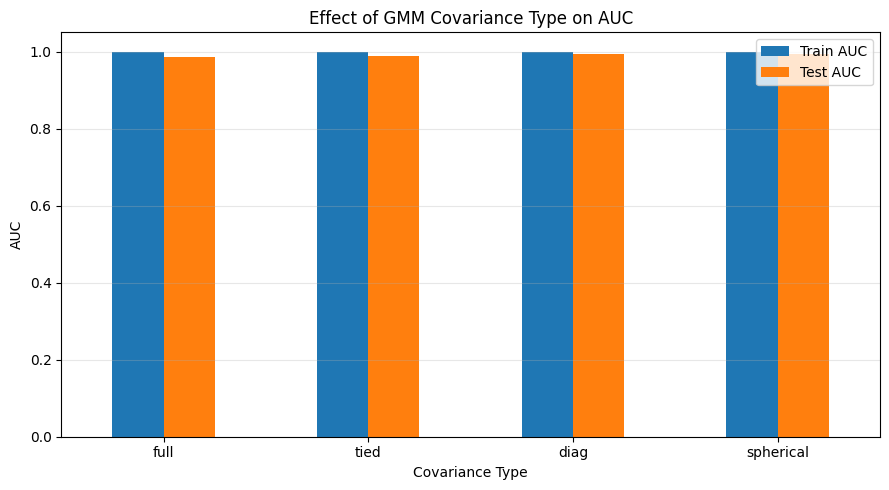

In [51]:
train_df, test_df = train_test_split(
    binary_iris,
    test_size=0.4,
    random_state=3,
    stratify=binary_iris["species"],
)

X_train = train_df[measurement_cols]
X_test = test_df[measurement_cols]

y_train = (train_df["species"] == "virginica").astype(int)
y_test = (test_df["species"] == "virginica").astype(int)

results = []

for covariance in ["full", "tied", "diag", "spherical"]:
    settings = {
        "n_components": 2,
        "covariance_type": covariance,
        "n_init": 5,
        "reg_covar": 1e-6,
        "random_state": 0,
    }

    gmm_versicolor = GaussianMixture(**settings).fit(
        X_train.loc[y_train == 0]
    )
    gmm_virginica = GaussianMixture(**settings).fit(
        X_train.loc[y_train == 1]
    )

    train_scores = (
        gmm_virginica.score_samples(X_train)
        - gmm_versicolor.score_samples(X_train)
    )
    test_scores = (
        gmm_virginica.score_samples(X_test)
        - gmm_versicolor.score_samples(X_test)
    )

    results.append({
        "Covariance type": covariance,
        "Train AUC": roc_auc_score(y_train, train_scores),
        "Test AUC": roc_auc_score(y_test, test_scores),
    })

covariance_results = pd.DataFrame(results)
print(covariance_results.round(4).to_string(index=False))

covariance_results.set_index("Covariance type").plot.bar(
    figsize=(9, 5),
    rot=0,
)

plt.xlabel("Covariance Type")
plt.ylabel("AUC")
plt.title("Effect of GMM Covariance Type on AUC")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()